LAB 05 — Sequence Classification

Code và output được giữ theo lượt chạy đã lưu: 10 epoch trên CPU, Python 3.10.8,
PyTorch 2.1.0+cpu và scikit-learn 1.7.2. Các nhận xét sau mỗi phần gắn với đúng
các bảng và prediction của lượt chạy này, không lấy số liệu của lượt chạy 3 epoch trước.
Khi chạy lại với cấu hình hoặc output khác cần cập nhật phần nhận xét tương ứng.

Mọi kết quả số được lưu vào một file lab05_results.csv ở cell cuối.
Các phần Prediction trước experiment và reflection cá nhân trong bài viết riêng
cần được đối chiếu với kết quả; phần đối chiếu sau experiment không thay thế dự đoán ban đầu.


In [1]:
import re
import sys
import time
import random
import platform
import zipfile
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay,
)

LAB_DIR = Path(r"D:\Study\Study_Class\Semester_7\NLP\Lab\lab05")
DATA_PATH = LAB_DIR.parent / "data" / "archive.zip"
OUTPUT_DIR = LAB_DIR
RESULTS_PATH = OUTPUT_DIR / "lab05_results.csv"

RANDOM_SEED = 2026
MAX_LENGTHS = [50, 100, 200]
MODEL_MAX_LENGTH = 100
MAX_VOCAB_SIZE = 20_000
EMBED_DIM = 64
HIDDEN_DIM = 64
BATCH_SIZE = 128
EPOCHS = 10
LEARNING_RATE = 1e-3
GRADIENT_CLIP = 1.0
PAD_ID, UNK_ID = 0, 1
LABEL_TO_ID = {"negative": 0, "positive": 1}
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.set_num_threads(4)

def set_seed(seed=RANDOM_SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed()
if not DATA_PATH.exists():
    raise FileNotFoundError(DATA_PATH)
if str(LAB_DIR) not in sys.path:
    sys.path.insert(0, str(LAB_DIR))

TOKEN_PATTERN = re.compile(r"[a-z0-9]+(?:'[a-z0-9]+)?")

def tokenize(text):
    return TOKEN_PATTERN.findall(str(text).lower())

print("Dataset:", DATA_PATH)
print("Device:", DEVICE, "| PyTorch:", torch.__version__)
print("Epochs:", EPOCHS, "| Batch size:", BATCH_SIZE)


Dataset: D:\Study\Study_Class\Semester_7\NLP\Lab\data\archive.zip
Device: cpu | PyTorch: 2.1.0+cpu
Epochs: 10 | Batch size: 128


11. Experiment 1 — Dataset inspection

Sequence length được đếm bằng đúng tokenizer dùng cho model.
Kiểm tra nhãn mâu thuẫn và loại review trùng trước khi chia dữ liệu.


,Experiment,Model,Raw samples,Samples,Classes,Missing texts,Missing labels,Raw duplicate texts,Removed duplicate texts,Min length,Median length,Mean length,Max length,Length p90,Length p95
0,Experiment 1,IMDb dataset,50000,49578,2,0,0,418,422,6,173.0,231.21,2473,451.3,589.0


Removed normalized duplicate reviews: 422


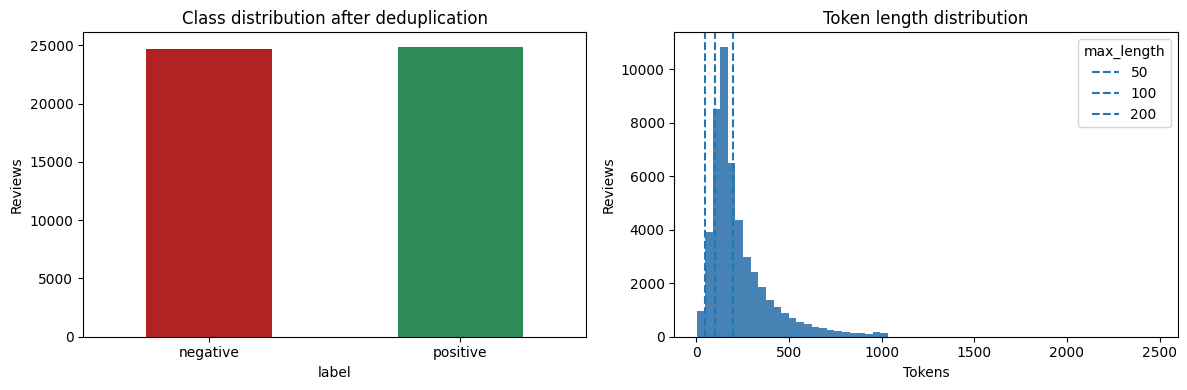

In [2]:
with zipfile.ZipFile(DATA_PATH) as archive:
    with archive.open("IMDB Dataset.csv") as file:
        raw_df = pd.read_csv(file).rename(
            columns={"review": "text", "sentiment": "label"}
        )

raw_count = len(raw_df)
missing_texts = int(raw_df["text"].isna().sum())
missing_labels = int(raw_df["label"].isna().sum())
raw_duplicates = int(raw_df["text"].duplicated().sum())
df = raw_df.dropna(subset=["text", "label"]).copy()
df["text_clean"] = (
    df["text"].astype(str)
    .str.replace(r"<br\s*/?>", " ", regex=True)
    .str.replace(r"\s+", " ", regex=True).str.strip()
)
df = df[df["text_clean"].ne("")].copy()
assert set(df["label"]).issubset(LABEL_TO_ID), "Unexpected labels"

# Same normalized text must never occur in different data splits.
df["text_key"] = df["text_clean"].str.lower()
conflicts = df.groupby("text_key")["label"].nunique()
if (conflicts > 1).any():
    raise ValueError("Duplicate reviews have conflicting labels; inspect first.")
clean_duplicates = int(df["text_key"].duplicated().sum())
df = df.drop_duplicates("text_key").reset_index(drop=True)
df["token_count"] = df["text_clean"].map(lambda text: len(tokenize(text)))

experiment1_result = pd.DataFrame([{
    "Experiment": "Experiment 1", "Model": "IMDb dataset",
    "Raw samples": raw_count, "Samples": len(df),
    "Classes": df["label"].nunique(),
    "Missing texts": missing_texts, "Missing labels": missing_labels,
    "Raw duplicate texts": raw_duplicates,
    "Removed duplicate texts": clean_duplicates,
    "Min length": df["token_count"].min(),
    "Median length": df["token_count"].median(),
    "Mean length": df["token_count"].mean(),
    "Max length": df["token_count"].max(),
    "Length p90": df["token_count"].quantile(0.90),
    "Length p95": df["token_count"].quantile(0.95),
}])
display(experiment1_result.round(2))
print("Removed normalized duplicate reviews:", clean_duplicates)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df["label"].value_counts().reindex(["negative", "positive"]).plot(
    kind="bar", ax=axes[0], color=["firebrick", "seagreen"], rot=0
)
axes[0].set_title("Class distribution after deduplication")
axes[0].set_ylabel("Reviews")
axes[1].hist(df["token_count"], bins=60, color="steelblue")
for length in MAX_LENGTHS:
    axes[1].axvline(length, linestyle="--", label=str(length))
axes[1].set(title="Token length distribution", xlabel="Tokens", ylabel="Reviews")
axes[1].legend(title="max_length")
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "dataset_analysis.png", dpi=160, bbox_inches="tight")
plt.show()


Nhận xét Experiment 1 và câu hỏi chọn max_length

Dataset ban đầu có 50.000 review thuộc hai lớp positive và negative, không có text hoặc nhãn bị thiếu. Có 418 bản ghi trùng theo text gốc. Sau khi thay thẻ xuống dòng bằng khoảng trắng, chuẩn hóa khoảng trắng và chuyển sang chữ thường để so sánh, số bản ghi trùng bị loại là 422. Dữ liệu còn 49.578 review; chênh lệch giữa 418 và 422 do một số review chỉ khác cách viết hoa hoặc khoảng trắng nên chỉ được nhận diện là trùng sau chuẩn hóa.

Sau khi loại trùng, lớp negative có 24.696 review và positive có 24.882 review, tương ứng khoảng 49,81% và 50,19%. Hai lớp gần cân bằng, nên accuracy có ý nghĩa tham khảo; tuy nhiên vẫn cần xem precision, recall và F1 để biết model nghiêng về dự đoán lớp nào. Việc loại trùng được thực hiện trước split để một nội dung không vừa xuất hiện trong train vừa xuất hiện trong validation hoặc test.

Độ dài được đo bằng tokenizer thực sự dùng cho model: ngắn nhất 6 token, trung vị 173 token, trung bình 231,21 token và dài nhất 2.473 token. Trung bình lớn hơn trung vị và có một số review rất dài cho thấy phân phối lệch phải. Phân vị 90 là 451,3 token và phân vị 95 là 589 token; chọn độ dài theo review dài nhất sẽ tốn nhiều padding cho phần lớn mẫu.

Để chọn max_length cần kết hợp phân phối độ dài, phần trăm token giữ lại, tỷ lệ review bị cắt, validation loss và tài nguyên tính toán. Với train, max_length=100 chỉ giữ 41,81% token và cắt 87,70% review, nên không thể coi 100 token là đủ context cho đa số văn bản. max_length=200 giữ khoảng 69,00% token và chỉ cắt 40,70% review, nhưng vẫn chưa bao phủ các review dài ở đuôi phân phối. Trong ba cấu hình RNN đã thử, validation loss ở 200 token tốt nhất; vì vậy 200 là ứng viên hợp lý hơn nếu ưu tiên chất lượng và chấp nhận thời gian chạy tăng. Giá trị 100 trong so sánh RNN/LSTM/GRU là giới hạn context được cố định để so sánh công bằng giữa các architecture, không phải bằng chứng rằng 100 là tối ưu.


12. Tokenization, vocabulary và split

Chia phân tầng 60/20/20. Vocabulary chỉ học từ train.
PAD làm đầy tensor; UNK đại diện token ngoài vocabulary.
Padding không chứa thông tin ngôn ngữ; truncation loại token vượt giới hạn.


In [3]:
X_train, X_temp, y_train, y_temp = train_test_split(
    df["text_clean"], df["label"], test_size=0.4,
    random_state=RANDOM_SEED, stratify=df["label"],
)
X_valid, X_test, y_valid, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5,
    random_state=RANDOM_SEED, stratify=y_temp,
)
train_keys = set(X_train.str.lower())
valid_keys = set(X_valid.str.lower())
test_keys = set(X_test.str.lower())
assert train_keys.isdisjoint(valid_keys)
assert train_keys.isdisjoint(test_keys)
assert valid_keys.isdisjoint(test_keys)

split_results = pd.DataFrame([
    {"Experiment": "Dataset split", "Split": name,
     "Samples": len(labels), "Negative samples": int((labels == "negative").sum()),
     "Positive samples": int((labels == "positive").sum())}
    for name, labels in [("Train", y_train), ("Validation", y_valid), ("Test", y_test)]
])
display(split_results)
print("Duplicate content between splits: 0")

counter = Counter(token for text in X_train for token in tokenize(text))
vocab = {"<PAD>": PAD_ID, "<UNK>": UNK_ID}
for word, _ in counter.most_common(MAX_VOCAB_SIZE - 2):
    vocab[word] = len(vocab)

def encode(text):
    ids = [vocab.get(token, UNK_ID) for token in tokenize(text)]
    return ids if ids else [UNK_ID]

train_encoded = [encode(text) for text in X_train]
valid_encoded = [encode(text) for text in X_valid]
test_encoded = [encode(text) for text in X_test]
y_train_id = y_train.map(LABEL_TO_ID).to_numpy(dtype=np.float32)
y_valid_id = y_valid.map(LABEL_TO_ID).to_numpy(dtype=np.float32)
y_test_id = y_test.map(LABEL_TO_ID).to_numpy(dtype=np.float32)
print("Vocabulary size:", len(vocab))
print("Example tokens:", tokenize(X_train.iloc[0])[:15])
print("Example IDs:", train_encoded[0][:15])


,Experiment,Split,Samples,Negative samples,Positive samples
0,Dataset split,Train,29746,14817,14929
1,Dataset split,Validation,9916,4940,4976
2,Dataset split,Test,9916,4939,4977


Duplicate content between splits: 0
Vocabulary size: 20000
Example tokens: ['i', 'usually', 'enjoy', 'loretta', "young's", 'early', 'movies', 'her', 'acting', 'back', 'then', 'was', 'light', 'and', 'breezy']
Example IDs: [10, 636, 359, 8350, 16289, 403, 96, 40, 110, 141, 91, 13, 626, 3, 12155]


Nhận xét split, tokenizer và vocabulary

Train có 29.746 mẫu, gồm 14.817 negative và 14.929 positive. Validation có 9.916 mẫu, gồm 4.940 negative và 4.976 positive. Test có 9.916 mẫu, gồm 4.939 negative và 4.977 positive. Các tỷ lệ xấp xỉ 60/20/20 và phân phối nhãn được giữ gần giống nhau nhờ stratified split. Assertions xác nhận không có text chuẩn hóa trùng giữa ba tập. Đây là kiểm tra rò rỉ do trùng nội dung, không phải cam kết rằng dữ liệu hoàn toàn không có mọi loại thiên lệch khác.

Đây là word-level tokenization: một review được biến thành chuỗi các token từ, không phải biến mỗi câu thành một token. Ví dụ output bắt đầu bằng các token 'i', 'usually', 'enjoy', 'loretta', "young's". Tokenizer chuyển chữ thường, bỏ dấu câu và giữ một số từ có dấu nháy như "doesn't" trong một token. Cách này giúp giữ dấu hiệu phủ định, nhưng cũng bỏ thông tin viết hoa và dấu câu; nó chưa giải quyết riêng sarcasm hoặc phạm vi của phủ định.

Vocabulary có 20.000 phần tử, gồm PAD có ID 0, UNK có ID 1 và tối đa 19.998 token phổ biến nhất từ train. Token trong validation/test không thuộc vocabulary được đổi thành UNK; không dùng các tập này để quyết định từ nào vào vocabulary. PAD chỉ lấp chỗ trống để tạo tensor cùng kích thước. UNK biểu diễn một từ thực sự xuất hiện nhưng model không có embedding riêng. Hai ký hiệu có vai trò khác nhau: PAD không được xử lý như thông tin của review, còn UNK vẫn nằm trong chuỗi đầu vào và có thể ảnh hưởng hidden state.


13. Padding và truncation

Báo cáo tỷ lệ token giữ lại theo từng split. Khi chọn max_length, dùng phân phối
độ dài và validation; test không được dùng để chọn hyperparameters.


In [4]:
def make_padded_tensor(encoded_sequences, max_length):
    X = torch.full((len(encoded_sequences), max_length), PAD_ID, dtype=torch.long)
    lengths = torch.empty(len(encoded_sequences), dtype=torch.long)
    for i, ids in enumerate(encoded_sequences):
        ids = ids[:max_length]
        lengths[i] = len(ids)
        X[i, :len(ids)] = torch.tensor(ids, dtype=torch.long)
    return X, lengths

def calculate_retained_percentage(max_length, sequences=None):
    sequences = train_encoded if sequences is None else sequences
    lengths = np.array([len(ids) for ids in sequences])
    return float(100 * np.minimum(lengths, max_length).sum() / lengths.sum())

def create_loader(encoded_sequences, labels, max_length, shuffle=False):
    X, lengths = make_padded_tensor(encoded_sequences, max_length)
    dataset = TensorDataset(X, lengths, torch.tensor(labels, dtype=torch.float32))
    generator = torch.Generator().manual_seed(RANDOM_SEED)
    return DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=shuffle, generator=generator)

retention_results = pd.DataFrame([
    {"Experiment": "Token retention", "Split": name, "Max length": length,
     "Tokens retained (%)": calculate_retained_percentage(length, sequences),
     "Truncated reviews (%)": 100 * np.mean([len(ids) > length for ids in sequences])}
    for name, sequences in [("Train", train_encoded), ("Validation", valid_encoded),
                            ("Test", test_encoded)]
    for length in MAX_LENGTHS
])
display(retention_results.round(2))


,Experiment,Split,Max length,Tokens retained (%),Truncated reviews (%)
0,Token retention,Train,50,21.65,97.49
1,Token retention,Train,100,41.81,87.70
2,Token retention,Train,200,69.00,40.70
3,Token retention,Validation,50,21.33,97.48
4,Token retention,Validation,100,41.22,87.35
5,Token retention,Validation,200,68.23,41.39
6,Token retention,Test,50,21.39,97.74
7,Token retention,Test,100,41.33,87.76
8,Token retention,Test,200,68.30,41.08


Nhận xét padding và truncation theo từng split

Trong train, các giới hạn 50/100/200 lần lượt giữ 21,65%/41,81%/69,00% token và làm 97,49%/87,70%/40,70% review bị truncate. Trong validation, tỷ lệ token giữ lại là 21,33%/41,22%/68,23%; trong test là 21,39%/41,33%/68,30%. Các tỷ lệ giữa các split tương đối gần nhau, nên không thấy một split có phân phối độ dài khác hẳn hai split còn lại qua các thống kê này.

Phần trăm token giữ lại không phải phần trăm review được giữ nguyên. Ví dụ train ở 200 token vẫn mất khoảng 31,00% tổng token, dù khoảng 59,30% review không bị cắt. Các review dài đóng góp nhiều vào số token bị loại. Ngược lại, 50 token chỉ giữ nguyên khoảng 2,51% review train; đây là giới hạn context rất mạnh trên dataset này.

Padding thêm PAD vào cuối review ngắn nhưng không xóa từ gốc. Truncation lấy prefix và loại hẳn các token ở phía sau, nên có thể xóa kết luận sentiment, câu đổi ý sau 'but', hoặc đối tượng mà các từ khen/chê đang nói tới. pack_padded_sequence dùng độ dài thật để recurrent layer dừng ở token cuối có nội dung. Chỉ đặt padding_idx=0 cho embedding chưa đủ để bảo đảm RNN bỏ qua mọi bước PAD; packed sequence mới giúp tránh cập nhật hidden state qua các vị trí padding trong pipeline này.


6 và 14. RNN forward và đối chiếu framework

Cell NumPy tự viết được kiểm tra với `torch.nn.RNNCell` dùng cùng weights và bias.
Phần training dùng framework theo phạm vi đề cho phép.


In [5]:
from rnn_cell import SimpleRNNCell

cell = SimpleRNNCell(input_size=2, hidden_size=2)
cell.W_xh = np.array([[0.5, 0.2], [0.1, 0.4]])
cell.W_hh = np.array([[0.3, 0.1], [0.2, 0.5]])
cell.b_h = np.zeros(2)
x_t = np.array([1.0, 0.0])
h_prev = np.array([0.5, 0.2])
input_part = cell.W_xh @ x_t
recurrent_part = cell.W_hh @ h_prev
a_t = input_part + recurrent_part + cell.b_h
h_numpy = cell.forward(x_t, h_prev)

reference = nn.RNNCell(2, 2, nonlinearity="tanh").double()
with torch.no_grad():
    reference.weight_ih.copy_(torch.tensor(cell.W_xh))
    reference.weight_hh.copy_(torch.tensor(cell.W_hh))
    reference.bias_ih.copy_(torch.tensor(cell.b_h))
    reference.bias_hh.zero_()
    h_torch = reference(torch.tensor(x_t), torch.tensor(h_prev)).numpy()
np.testing.assert_allclose(h_numpy, h_torch, rtol=1e-10, atol=1e-10)
core_results = pd.DataFrame([
    {"Experiment": "Core RNN check", "Case": str(i),
     "Preactivation": a_t[i], "NumPy hidden": h_numpy[i],
     "PyTorch hidden": h_torch[i], "Absolute error": abs(h_numpy[i] - h_torch[i])}
    for i in range(2)
])
print("W_xh @ x_t =", input_part)
print("W_hh @ h_prev =", recurrent_part)
print("a_t =", a_t, "| h_t =", h_numpy)
display(core_results)


W_xh @ x_t = [0.5 0.1]
W_hh @ h_prev = [0.17 0.2 ]
a_t = [0.67 0.3 ] | h_t = [0.58497988 0.29131261]


,Experiment,Case,Preactivation,NumPy hidden,PyTorch hidden,Absolute error
0,Core RNN check,0,0.67,0.584980,0.584980,1.110223e-16
1,Core RNN check,1,0.30,0.291313,0.291313,0.000000e+00


Giải thích phép tính RNN và computation graph

Với input [1; 0], thành phần từ input là Wxh x = [0,5; 0,1]. Thành phần từ trạng thái trước là Whh h trước = [0,3×0,5 + 0,1×0,2; 0,2×0,5 + 0,5×0,2] = [0,17; 0,20]. Bias bằng 0 nên tổng trước hàm kích hoạt là [0,67; 0,30]. Áp dụng tanh theo từng phần tử cho hidden state mới [0,58497988; 0,29131261]. Đây là hidden state sau một timestep, chưa phải xác suất positive.

Computation graph có hai nhánh cùng đi tới phép cộng: nhánh input qua Wxh và nhánh hidden state trước qua Whh. Sau khi cộng bias, tanh tạo trạng thái mới. Vì vậy cùng một từ có thể tạo hidden state khác khi xuất hiện sau những prefix khác nhau. Wxh và Whh được chia sẻ qua các timestep; model không học một bộ weights riêng cho từng vị trí.

Cell NumPy và torch.nn.RNNCell được gán cùng weights; bias của framework được đặt sao cho tổng hai bias bằng bias của cell tự viết. Output có sai số tuyệt đối khoảng 1,11×10^-16 ở phần tử thứ nhất và 0 ở phần tử thứ hai, nằm trong sai số dấu phẩy động. Kết quả xác nhận phép forward của input kiểm tra khớp framework. Kiểm tra này không tự chứng minh phần backward hoặc toàn bộ training framework được tự implement; các experiment sử dụng recurrent layer của PyTorch.


Trả lời mục 7 — Information flow

Với chuỗi 'I did not like this movie', model cập nhật theo thứ tự: h1 = f(embedding('I'), h0), h2 = f(embedding('did'), h1), h3 = f(embedding('not'), h2), h4 = f(embedding('like'), h3), h5 = f(embedding('this'), h4), h6 = f(embedding('movie'), h5). h1 nhận thông tin về token đầu; h2 tiếp tục nhận prefix 'I did'; h3 có thể đưa dấu hiệu phủ định vào trạng thái. Khi đọc 'like', model nhận cả embedding của 'like' và h3 nên có cơ chế kết hợp từ mang nghĩa tích cực với thông tin 'not' trước đó. h5 và h6 tiếp tục cập nhật prefix có cả cụm 'not like'.

Hidden state là vector được học, không có bảo đảm rằng một chiều cố định chỉ lưu 'not', và thông tin trước đó có thể bị suy giảm hoặc ghi đè. Cơ chế cho phép sử dụng phủ định không có nghĩa model luôn diễn giải đúng phạm vi phủ định. Ở Application, thêm 'not' làm xác suất positive giảm và đổi nhãn; đó là bằng chứng cụ thể cho một cặp câu, không phải bảo đảm cho mọi câu phủ định.

Average Word2Vec vẫn chứa đóng góp của vector 'not', nhưng phép lấy trung bình không lưu quan hệ thứ tự 'not' đứng trước và bổ nghĩa cho 'like'. Đảo vị trí các token mà giữ nguyên số lần xuất hiện sẽ cho cùng vector trung bình. RNN có thể phân biệt các thứ tự này do trạng thái được cập nhật nối tiếp.


Trả lời mục 8 — Sequence order

Hai câu 'dog bites man' và 'man bites dog' có cùng ba token và cùng số lần xuất hiện. Average Word2Vec của cả hai bằng (vector dog + vector bites + vector man)/3, nên không phân biệt được ai là chủ thể và ai là đối tượng chỉ từ representation trung bình này. TF-IDF unigram cũng cho cùng vector đếm/trọng số trong trường hợp này.

RNN đọc 'dog' trước ở câu thứ nhất và 'man' trước ở câu thứ hai, nên hidden state đầu tiên có thể khác. Khi đọc 'bites', input token giống nhau nhưng hidden state trước khác, rồi bước cuối tiếp tục nhận những token khác nhau. Do đó phép hợp thành f(man, f(bites, f(dog, h0))) có thể khác f(dog, f(bites, f(man, h0))). Đây là khả năng phân biệt thứ tự của architecture, không phải khẳng định mọi bộ weights đều tạo hai dự đoán khác nhau. Kiểm tra xáo thứ tự trong notebook cung cấp bằng chứng rằng các model đã train thực sự có thay đổi prediction khi thay đổi thứ tự.


Model, training và evaluation

Ba architecture dùng chung vocabulary, embedding size, hidden size, optimizer,
learning rate, batch order và epochs. Checkpoint được chọn bằng validation loss.
Precision/Recall/F1 báo cáo cho lớp positive. Thời gian bao gồm training và
validation mỗi epoch, không gồm test; baseline gồm fit TF-IDF và LR.


In [6]:
class RecurrentClassifier(nn.Module):
    def __init__(self, architecture):
        super().__init__()
        self.architecture = architecture
        self.embedding = nn.Embedding(len(vocab), EMBED_DIM, padding_idx=PAD_ID)
        recurrent_class = {"RNN": nn.RNN, "LSTM": nn.LSTM, "GRU": nn.GRU}[architecture]
        self.recurrent = recurrent_class(EMBED_DIM, HIDDEN_DIM, batch_first=True)
        self.classifier = nn.Linear(HIDDEN_DIM, 1)

    def forward(self, X, lengths):
        packed = nn.utils.rnn.pack_padded_sequence(
            self.embedding(X), lengths.cpu(), batch_first=True, enforce_sorted=False
        )
        _, state = self.recurrent(packed)
        hidden = state[0] if self.architecture == "LSTM" else state
        return self.classifier(hidden[-1]).squeeze(1)

def metrics(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
    }

def show_confusion_matrix(y_true, y_pred, title):
    fig, axis = plt.subplots(figsize=(4, 3.5))
    ConfusionMatrixDisplay.from_predictions(
        y_true, y_pred, labels=[0, 1], display_labels=["negative", "positive"],
        ax=axis, cmap="Blues", colorbar=False, values_format="d",
    )
    axis.set_title(title)
    plt.tight_layout()
    plt.show()

def evaluate(model, loader, criterion):
    model.eval()
    total_loss = 0.0
    y_true, probabilities = [], []
    with torch.no_grad():
        for X, lengths, y in loader:
            logits = model(X.to(DEVICE), lengths)
            loss = criterion(logits, y.to(DEVICE))
            total_loss += loss.item() * len(y)
            y_true.extend(y.long().tolist())
            probabilities.extend(torch.sigmoid(logits).cpu().tolist())
    y_true = np.asarray(y_true)
    probabilities = np.asarray(probabilities)
    y_pred = (probabilities >= 0.5).astype(int)
    return {"loss": total_loss / len(y_true), "metrics": metrics(y_true, y_pred),
            "y_true": y_true, "y_pred": y_pred, "probabilities": probabilities}

def train_model(architecture, max_length):
    set_seed()
    train_loader = create_loader(train_encoded, y_train_id, max_length, True)
    valid_loader = create_loader(valid_encoded, y_valid_id, max_length)
    test_loader = create_loader(test_encoded, y_test_id, max_length)
    model = RecurrentClassifier(architecture).to(DEVICE)
    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    history = {"train_loss": [], "validation_loss": [], "validation_f1": []}
    best_loss, best_epoch, best_state = float("inf"), 0, None
    if DEVICE.type == "cuda":
        torch.cuda.reset_peak_memory_stats()
        torch.cuda.synchronize()
    start = time.perf_counter()
    for epoch in range(1, EPOCHS + 1):
        model.train()
        total_loss = 0.0
        for X, lengths, y in train_loader:
            optimizer.zero_grad()
            logits = model(X.to(DEVICE), lengths)
            loss = criterion(logits, y.to(DEVICE))
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), GRADIENT_CLIP)
            optimizer.step()
            total_loss += loss.item() * len(y)
        train_loss = total_loss / len(train_loader.dataset)
        validation = evaluate(model, valid_loader, criterion)
        history["train_loss"].append(train_loss)
        history["validation_loss"].append(validation["loss"])
        history["validation_f1"].append(validation["metrics"]["F1"])
        if validation["loss"] < best_loss:
            best_loss, best_epoch = validation["loss"], epoch
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        print(f"{architecture} length={max_length} epoch={epoch}/{EPOCHS} "
              f"train={train_loss:.4f} val={validation['loss']:.4f} "
              f"val_F1={validation['metrics']['F1']:.4f}")
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    training_time = time.perf_counter() - start
    memory_mb = (torch.cuda.max_memory_allocated() / 1024**2
                 if DEVICE.type == "cuda" else np.nan)
    model.load_state_dict(best_state)
    validation = evaluate(model, valid_loader, criterion)
    test = evaluate(model, test_loader, criterion)
    result = {
        "Model": architecture, "Architecture": architecture, "Representation": "Embedding",
        "Input scope": f"First {max_length} tokens", "Max length": max_length,
        "Tokens retained (%)": calculate_retained_percentage(max_length),
        "Parameters": sum(p.numel() for p in model.parameters() if p.requires_grad),
        "Training time (s)": training_time, "Epochs": EPOCHS, "Best epoch": best_epoch,
        "Vocabulary size": len(vocab), "Embedding dimension": EMBED_DIM,
        "Hidden dimension": HIDDEN_DIM, "Batch size": BATCH_SIZE,
        "Optimizer": "Adam", "Learning rate": LEARNING_RATE,
        "Validation loss": validation["loss"], "Validation F1": validation["metrics"]["F1"],
        "Test loss": test["loss"], "Memory (MB)": memory_mb, **test["metrics"],
    }
    model.cpu()
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    return {"result": result, "history": history, "model": model,
            "y_true": test["y_true"], "y_pred": test["y_pred"],
            "probabilities": test["probabilities"]}

def predict_texts(model, texts, max_length=MODEL_MAX_LENGTH):
    encoded = [encode(text) for text in texts]
    loader = create_loader(encoded, np.zeros(len(texts)), max_length)
    model.to(DEVICE).eval()
    probabilities = []
    with torch.no_grad():
        for X, lengths, _ in loader:
            logits = model(X.to(DEVICE), lengths)
            probabilities.extend(torch.sigmoid(logits).cpu().tolist())
    model.cpu()
    return np.asarray(probabilities)


Trả lời mục 9, 16 và 18 — Gradient, hidden state, LSTM và GRU

RNN phải đưa thông tin từ token đầu tới trạng thái cuối qua nhiều bước cập nhật. Khi backpropagation through time, gradient tới bước xa chứa tích các Jacobian của nhiều timestep. Nếu hướng truyền tín hiệu bị co lại lặp đi lặp lại, gradient có thể rất nhỏ và weights khó học ảnh hưởng của token ở xa; nếu bị khuếch đại liên tục, gradient có thể bùng nổ. Với tanh, các vùng bão hòa còn có đạo hàm nhỏ. Gradient clipping ở đây giới hạn độ lớn gradient khi cập nhật để giảm exploding gradient, nhưng không phục hồi gradient đã biến mất.

LSTM duy trì cell state riêng và hidden state. Forget gate nhân vào thông tin cũ, input gate điều chỉnh lượng candidate được ghi thêm, output gate quyết định phần cell state biểu hiện ra hidden state. Đường cập nhật cell state dạng cộng có thể giúp duy trì thông tin tốt hơn RNN khi gates phù hợp, nhưng không phải cơ chế nhớ vô hạn. GRU không có cell state riêng; update gate điều chỉnh mức giữ trạng thái cũ và reset gate điều chỉnh đóng góp của trạng thái cũ khi tạo candidate. Với cùng kích thước hidden, ba nhóm biến đổi của GRU thường ít hơn bốn nhóm của LSTM.

Trong pipeline này, embedding trả vector 64 chiều cho từng token, recurrent layer trả hidden state 64 chiều ở cuối phần review thực sự được đọc, linear layer biến nó thành một logit, sigmoid chuyển logit thành P(positive). BCEWithLogitsLoss nhận trực tiếp logit để tính binary cross-entropy ổn định số học; không đưa sigmoid vào trước criterion. Ngưỡng 0,5 được dùng thống nhất khi đổi xác suất thành nhãn.

Cấu hình của lượt chạy đang phân tích là 10 epoch, batch size 128, vocabulary 20.000, embedding dimension 64, hidden dimension 64, Adam với learning rate 0,001, seed 2026 và thiết bị CPU. Checkpoint mỗi model được chọn bằng validation loss thấp nhất. Architecture phục vụ kiểm tra sau đó được chọn bằng validation F1 của checkpoint đã chọn; không chọn bằng test F1.


Experiment 2 — Padding và truncation

Tăng độ dài giữ thêm context nhưng tăng chi phí; không giả định performance tăng đều.


c:\Users\User\AppData\Local\Programs\Python\Python310\lib\site-packages\requests\__init__.py:113: RequestsDependencyWarning: urllib3 (2.6.2) or chardet (7.4.3)/charset_normalizer (3.4.4) doesn't match a supported version!
  warnings.warn(


RNN length=50 epoch=1/10 train=0.6958 val=0.6920 val_F1=0.5293
RNN length=50 epoch=2/10 train=0.6750 val=0.6689 val_F1=0.5585
RNN length=50 epoch=3/10 train=0.6476 val=0.6527 val_F1=0.6498
RNN length=50 epoch=4/10 train=0.6266 val=0.6371 val_F1=0.6563
RNN length=50 epoch=5/10 train=0.5853 val=0.6258 val_F1=0.6809
RNN length=50 epoch=6/10 train=0.5463 val=0.6135 val_F1=0.7107
RNN length=50 epoch=7/10 train=0.5063 val=0.6086 val_F1=0.6994
RNN length=50 epoch=8/10 train=0.4680 val=0.6055 val_F1=0.7067
RNN length=50 epoch=9/10 train=0.4340 val=0.6054 val_F1=0.7140
RNN length=50 epoch=10/10 train=0.4024 val=0.6408 val_F1=0.7096


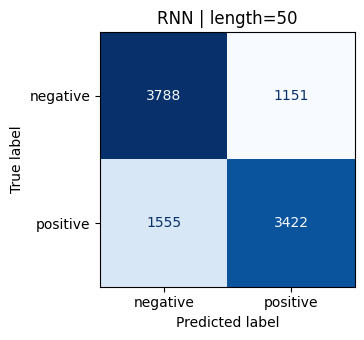

RNN length=100 epoch=1/10 train=0.6963 val=0.6932 val_F1=0.4972
RNN length=100 epoch=2/10 train=0.6793 val=0.6857 val_F1=0.5937
RNN length=100 epoch=3/10 train=0.6555 val=0.6459 val_F1=0.6591
RNN length=100 epoch=4/10 train=0.6238 val=0.6389 val_F1=0.6851
RNN length=100 epoch=5/10 train=0.5988 val=0.6301 val_F1=0.6290
RNN length=100 epoch=6/10 train=0.5705 val=0.6135 val_F1=0.6823
RNN length=100 epoch=7/10 train=0.5376 val=0.6028 val_F1=0.7067
RNN length=100 epoch=8/10 train=0.5072 val=0.5968 val_F1=0.7253
RNN length=100 epoch=9/10 train=0.4772 val=0.5872 val_F1=0.7102
RNN length=100 epoch=10/10 train=0.4493 val=0.6013 val_F1=0.7338


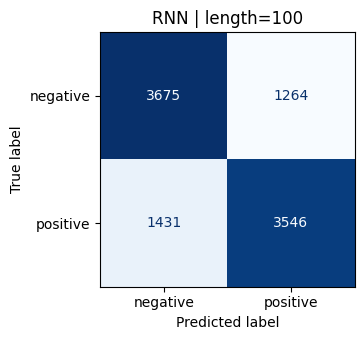

RNN length=200 epoch=1/10 train=0.6853 val=0.6691 val_F1=0.5851
RNN length=200 epoch=2/10 train=0.6239 val=0.5973 val_F1=0.6938
RNN length=200 epoch=3/10 train=0.5573 val=0.5784 val_F1=0.7295
RNN length=200 epoch=4/10 train=0.5147 val=0.5433 val_F1=0.7240
RNN length=200 epoch=5/10 train=0.4784 val=0.5300 val_F1=0.7641
RNN length=200 epoch=6/10 train=0.4401 val=0.5084 val_F1=0.7894
RNN length=200 epoch=7/10 train=0.4100 val=0.5028 val_F1=0.7928
RNN length=200 epoch=8/10 train=0.3801 val=0.5407 val_F1=0.7424
RNN length=200 epoch=9/10 train=0.3633 val=0.4980 val_F1=0.7998
RNN length=200 epoch=10/10 train=0.3310 val=0.4964 val_F1=0.7887


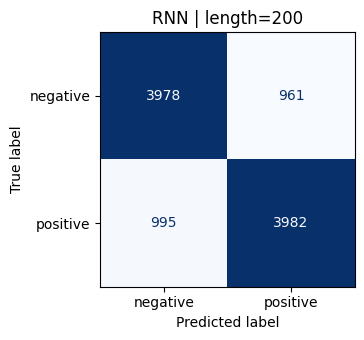

,Model,Max length,Tokens retained (%),Training time (s),Validation loss,Accuracy,F1
0,RNN,50,21.6488,148.3085,0.6054,0.7271,0.7166
1,RNN,100,41.8103,298.0611,0.5872,0.7282,0.7246
2,RNN,200,68.9951,1051.7707,0.4964,0.8027,0.8028


In [7]:
experiment2_outputs = {}
for max_length in MAX_LENGTHS:
    output = train_model("RNN", max_length)
    experiment2_outputs[max_length] = output
    show_confusion_matrix(output["y_true"], output["y_pred"], f"RNN | length={max_length}")
experiment2_results = pd.DataFrame([
    {"Experiment": "Experiment 2", **output["result"]}
    for output in experiment2_outputs.values()
])
display(experiment2_results[["Model", "Max length", "Tokens retained (%)",
                            "Training time (s)", "Validation loss", "Accuracy", "F1"]].round(4))


Nhận xét Experiment 2 và trả lời hai câu hỏi về max_length

RNN ở 50 token giữ 21,6488% token train, chạy 148,3085 giây, accuracy 0,7271 và F1 0,7166. Ở 100 token, tỷ lệ giữ lại tăng lên 41,8103%, thời gian 298,0611 giây, accuracy 0,7282 và F1 0,7246. Ở 200 token, model giữ 68,9951% token, chạy 1.051,7707 giây, accuracy 0,8027 và F1 0,8028. Validation loss tốt nhất lần lượt là 0,6054, 0,5872 và 0,4964.

Tăng từ 50 lên 100 gần gấp đôi thời gian, nhưng F1 chỉ tăng khoảng 0,0080, tức 0,80 điểm phần trăm khi biểu diễn F1 trên thang phần trăm. Tăng từ 100 lên 200 làm thời gian tăng khoảng 3,53 lần, đồng thời F1 tăng khoảng 0,0782 và validation loss giảm rõ hơn. Vì vậy mức cải thiện không tỷ lệ đều với số token được thêm. Trong đúng ba cấu hình của lượt chạy này, cả accuracy và F1 đều tăng theo max_length; không nên mô tả kết quả này thành '100 kém 50' như một lượt chạy khác.

Câu hỏi tăng max_length có luôn cải thiện performance không: không có bảo đảm như vậy. Lượt chạy hiện tại ủng hộ 200 hơn 50 và 100 trên các chỉ số đã đo, nhưng chỉ có ba mức độ dài, một seed và một cấu hình optimizer/hidden size. Context thêm vào có thể hữu ích, cũng có thể chứa nhiễu, gây khó tối ưu hoặc tăng overfitting. Không có kết quả ở độ dài lớn hơn 200 để khẳng định xu hướng sẽ tiếp tục.

Câu hỏi max_length quá nhỏ làm mất thông tin gì: có thể mất câu tổng kết khen/chê ở cuối review, vế đảo ý sau từ nối tương phản, hoặc thông tin cho biết lời khen đang nói về phim được đánh giá hay một phim khác. Error Analysis có review mà câu 'This film does not flatter Wayne' bắt đầu ở token 173 và review đổi từ chê subplot sang khen phim ở token 142; cả hai thông tin đều biến mất khi chỉ lấy 100 token đầu. Đây là ví dụ cụ thể của mất thông tin đầu vào, không chỉ là giả thuyết rằng RNN quên thông tin xa.


15. Experiment 3 — TF-IDF + Logistic Regression vs Simple RNN

Baseline dùng review đầy đủ, RNN chỉ đọc prefix theo max_length; vì vậy chênh lệch
F1 ở bảng này không thể quy hoàn toàn cho architecture. Kiểm tra word order riêng
bên dưới cho hai model nhận cùng token và cùng giới hạn độ dài.


,Model,Representation,Accuracy,Precision,Recall,F1,Training time (s)
0,Logistic Regression,TF-IDF unigram,0.9079,0.9038,0.9138,0.9088,8.6380
1,RNN,Embedding,0.7282,0.7372,0.7125,0.7246,298.0611


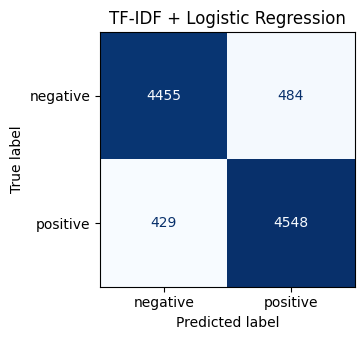

In [8]:
baseline_model = Pipeline([
    ("tfidf", TfidfVectorizer(min_df=2, ngram_range=(1, 1))),
    ("classifier", LogisticRegression(C=2.0, max_iter=1000, solver="liblinear",
                                      random_state=RANDOM_SEED)),
])
start = time.perf_counter()
baseline_model.fit(X_train, y_train)
baseline_time = time.perf_counter() - start
positive_class = list(baseline_model.classes_).index("positive")
baseline_probabilities = baseline_model.predict_proba(X_test)[:, positive_class]
baseline_pred_ids = (baseline_probabilities >= 0.5).astype(int)
baseline_result = {
    "Experiment": "Experiment 3", "Model": "Logistic Regression",
    "Architecture": "Logistic Regression", "Representation": "TF-IDF unigram",
    "Input scope": "Full review", "Training time (s)": baseline_time,
    "Parameters": baseline_model.named_steps["classifier"].coef_.size + 1,
    "Vocabulary size": len(baseline_model.named_steps["tfidf"].vocabulary_),
    "Optimizer iterations": int(baseline_model.named_steps["classifier"].n_iter_.max()),
    **metrics(y_test_id.astype(int), baseline_pred_ids),
}
rnn_exp3_result = {"Experiment": "Experiment 3",
                   **experiment2_outputs[MODEL_MAX_LENGTH]["result"]}
experiment3_results = pd.DataFrame([baseline_result, rnn_exp3_result])
display(experiment3_results[["Model", "Representation", "Accuracy", "Precision",
                            "Recall", "F1", "Training time (s)"]].round(4))
show_confusion_matrix(y_test_id.astype(int), baseline_pred_ids, "TF-IDF + Logistic Regression")


Nhận xét Experiment 3 — Baseline và giới hạn của phép so sánh

TF-IDF + Logistic Regression đạt accuracy 0,9079, precision 0,9038, recall 0,9138 và F1 0,9088 trong 8,6380 giây. RNN ở 100 token đạt accuracy 0,7282, precision 0,7372, recall 0,7125 và F1 0,7246 trong 298,0611 giây. Baseline có F1 cao hơn khoảng 0,1841 và thời gian fit nhỏ hơn nhiều; thời gian RNN bằng khoảng 34,51 lần baseline theo cách đo hiện tại.

Kết quả cho thấy khả năng xử lý sequence không tự động biến thành chất lượng classification cao hơn. Tuy nhiên, đây chưa phải phép so sánh chỉ khác architecture: TF-IDF được đọc review đầy đủ và có 48.465 features, còn RNN chỉ dùng 100 token đầu và vocabulary 20.000. Baseline có 48.466 tham số classifier, trong khi RNN có 1.288.385 tham số gồm cả embedding. Baseline fit TF-IDF và LR, còn thời gian RNN bao gồm training và validation qua 10 epoch. Các khác biệt này cần được nêu khi nhận xét cost và performance.

Câu hỏi RNN có thực sự dùng thông tin sequence mà TF-IDF không dùng không được trả lời bằng việc chỉ nhìn F1 0,7246 so với 0,9088. Bằng chứng trực tiếp hơn là kiểm tra cùng tập token ở phần word order: vector TF-IDF không đổi, trong khi prediction của RNN đổi ở một phần đáng kể mẫu. Phần đó cho phép kết luận về độ nhạy với thứ tự, nhưng không loại bỏ mọi ảnh hưởng của thứ tự lên vị trí token cuối hoặc tính tự nhiên của câu.


19. Experiment 4 — RNN vs LSTM vs GRU

So sánh cả precision, recall, F1, thời gian và số tham số.
Architecture dùng cho các kiểm tra sau được chọn bằng validation F1, không dùng test F1.


LSTM length=100 epoch=1/10 train=0.6860 val=0.6596 val_F1=0.6551
LSTM length=100 epoch=2/10 train=0.6073 val=0.5585 val_F1=0.7219
LSTM length=100 epoch=3/10 train=0.4959 val=0.4805 val_F1=0.7906
LSTM length=100 epoch=4/10 train=0.4145 val=0.4689 val_F1=0.8002
LSTM length=100 epoch=5/10 train=0.3532 val=0.4461 val_F1=0.7903
LSTM length=100 epoch=6/10 train=0.3078 val=0.4416 val_F1=0.8065
LSTM length=100 epoch=7/10 train=0.2689 val=0.4583 val_F1=0.8183
LSTM length=100 epoch=8/10 train=0.2314 val=0.4769 val_F1=0.8224
LSTM length=100 epoch=9/10 train=0.1971 val=0.5409 val_F1=0.8237
LSTM length=100 epoch=10/10 train=0.1645 val=0.5100 val_F1=0.8203


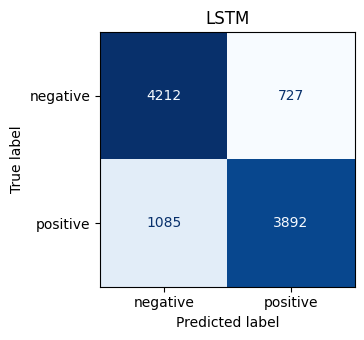

GRU length=100 epoch=1/10 train=0.6836 val=0.6252 val_F1=0.6907
GRU length=100 epoch=2/10 train=0.5632 val=0.5144 val_F1=0.7393
GRU length=100 epoch=3/10 train=0.4347 val=0.4392 val_F1=0.7979
GRU length=100 epoch=4/10 train=0.3629 val=0.4189 val_F1=0.8072
GRU length=100 epoch=5/10 train=0.3063 val=0.4103 val_F1=0.8218
GRU length=100 epoch=6/10 train=0.2557 val=0.4317 val_F1=0.8087
GRU length=100 epoch=7/10 train=0.2087 val=0.4432 val_F1=0.8243
GRU length=100 epoch=8/10 train=0.1659 val=0.5130 val_F1=0.8162
GRU length=100 epoch=9/10 train=0.1287 val=0.5787 val_F1=0.8272
GRU length=100 epoch=10/10 train=0.0988 val=0.6357 val_F1=0.8064


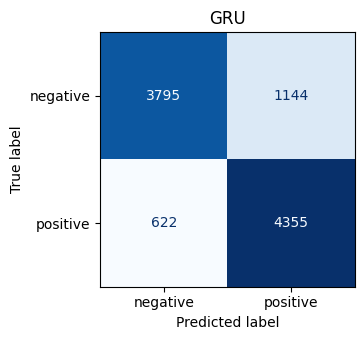

,Model,Parameters,Training time (s),Validation F1,Accuracy,Precision,Recall,F1
0,RNN,1288385,298.0611,0.7102,0.7282,0.7372,0.7125,0.7246
1,LSTM,1313345,919.8810,0.8065,0.8173,0.8426,0.7820,0.8112
2,GRU,1305025,635.1304,0.8218,0.8219,0.7920,0.8750,0.8314


Selected using validation: GRU


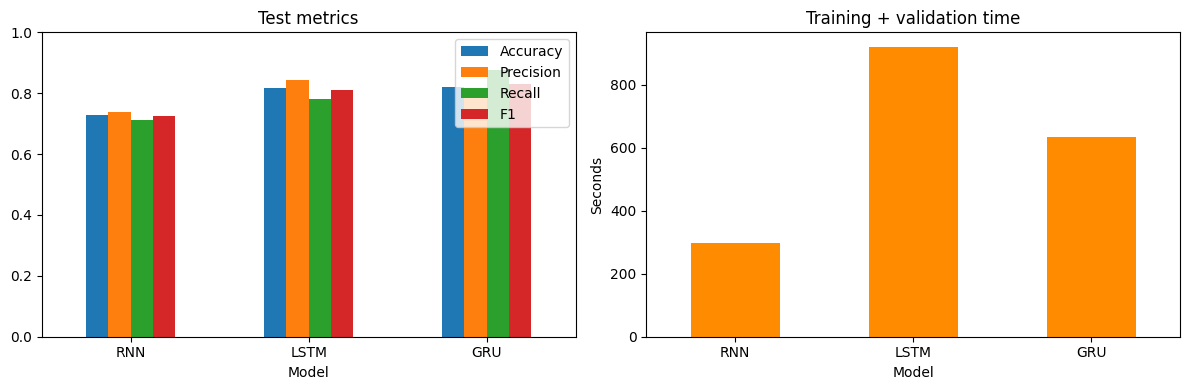

In [9]:
exp4_outputs = {"RNN": experiment2_outputs[MODEL_MAX_LENGTH]}
for architecture in ["LSTM", "GRU"]:
    output = train_model(architecture, MODEL_MAX_LENGTH)
    exp4_outputs[architecture] = output
    show_confusion_matrix(output["y_true"], output["y_pred"], architecture)
experiment4_results = pd.DataFrame([
    {"Experiment": "Experiment 4", **output["result"]}
    for output in exp4_outputs.values()
])
best_architecture = experiment4_results.sort_values(
    ["Validation F1", "Validation loss"], ascending=[False, True]
).iloc[0]["Model"]
best_model = exp4_outputs[best_architecture]["model"]
display(experiment4_results[["Model", "Parameters", "Training time (s)",
                            "Validation F1", "Accuracy", "Precision", "Recall", "F1"]].round(4))
print("Selected using validation:", best_architecture)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
experiment4_results.set_index("Model")[["Accuracy", "Precision", "Recall", "F1"]].plot(
    kind="bar", ax=axes[0], ylim=(0, 1), rot=0
)
experiment4_results.set_index("Model")["Training time (s)"].plot(
    kind="bar", ax=axes[1], color="darkorange", rot=0
)
axes[0].set_title("Test metrics")
axes[1].set(title="Training + validation time", ylabel="Seconds")
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "model_comparison.png", dpi=160, bbox_inches="tight")
plt.show()


Nhận xét Experiment 4 — RNN, LSTM và GRU

Ở cùng giới hạn 100 token, RNN có F1 0,7246, LSTM có F1 0,8112 và GRU có F1 0,8314. Accuracy tương ứng là 0,7282, 0,8173 và 0,8219. Cả LSTM và GRU cải thiện hơn RNN trong cấu hình đã thử; GRU đạt F1 cao nhất trong ba recurrent model, nhưng vẫn thấp hơn F1 0,9088 của baseline đọc toàn bộ review.

Không thể chỉ dựa vào accuracy để chọn giữa LSTM và GRU. LSTM có precision 0,8426, cao hơn 0,7920 của GRU; ngược lại recall của GRU là 0,8750, cao hơn 0,7820 của LSTM. GRU tìm được nhiều review positive hơn nhưng cũng tạo nhiều false positive hơn. Nếu ưu tiên hạn chế gán nhầm review negative thành positive thì LSTM có lợi thế trong lượt chạy này; nếu ưu tiên phát hiện positive và cân bằng theo positive-class F1 thì GRU phù hợp hơn. Việc chọn model ở đây vẫn dựa trên validation, không dựa vào nhu cầu được suy ra sau khi nhìn test.

RNN, LSTM và GRU có lần lượt 1.288.385, 1.313.345 và 1.305.025 tham số. Embedding chung đã chiếm 1.280.000 tham số, nên chênh lệch tổng số tham số giữa các model không lớn. GRU ít hơn LSTM 8.320 tham số. Về thời gian, RNN cần 298,0611 giây, LSTM 919,8810 giây và GRU 635,1304 giây; GRU nhanh hơn LSTM khoảng 30,96% trong lần đo này. Không nên kết luận tốc độ chỉ từ tổng số tham số vì gates, số phép biến đổi ở mỗi timestep và implementation cũng ảnh hưởng.

Checkpoint RNN được lấy ở epoch 9, LSTM ở epoch 6 và GRU ở epoch 5 theo validation loss. Validation F1 tại các checkpoint này là 0,7102, 0,8065 và 0,8218, nên chọn GRU cho các phần phân tích sau là phù hợp quy tắc đã đặt ra. Đây không phải F1 cao nhất của mọi epoch: ví dụ GRU ở epoch 9 có validation F1 0,8272 nhưng validation loss xấu hơn, nên không được chọn. Quy tắc chọn checkpoint theo loss cần được phân biệt với quy tắc chọn architecture theo F1.

So với prediction rằng cơ chế gates có thể hỗ trợ giữ context tốt hơn RNN, kết quả classification của LSTM/GRU là phù hợp về chiều hướng. Tuy nhiên, task này còn phụ thuộc từ sentiment cục bộ và phần prefix được giữ lại; chênh lệch F1 chưa chứng minh riêng cơ chế long-range dependency là nguyên nhân. Experiment 6 còn cho thấy model có F1 tổng thể cao không nhất thiết tốt nhất trên các câu nhân tạo kiểm tra vị trí từ.


Bằng chứng word order — kiểm tra bổ sung cho Experiment 3

Chỉ giữ 100 token đầu, sau đó xáo thứ tự trong prefix này. Hai điều kiện có cùng
token và cùng độ dài, không đổi weights. TF-IDF unigram phải bất biến.
Độ thay đổi prediction đo order sensitivity; không tự chứng minh model hiểu đúng ngữ nghĩa.
Đây là phân tích chẩn đoán trên test, không dùng để chọn model/hyperparameters.


,Experiment,Model,Max length,Samples,Original F1,Shuffled F1,F1 drop,Changed predictions (%),Mean probability change
0,Word order,Logistic Regression,100,9916,0.8505,0.8505,0.0000,0.0000,0.0000
1,Word order,RNN,100,9916,0.7246,0.7268,-0.0022,23.5175,0.1887
2,Word order,LSTM,100,9916,0.8112,0.7904,0.0208,9.4595,0.0922
3,Word order,GRU,100,9916,0.8314,0.8121,0.0193,10.4175,0.0977


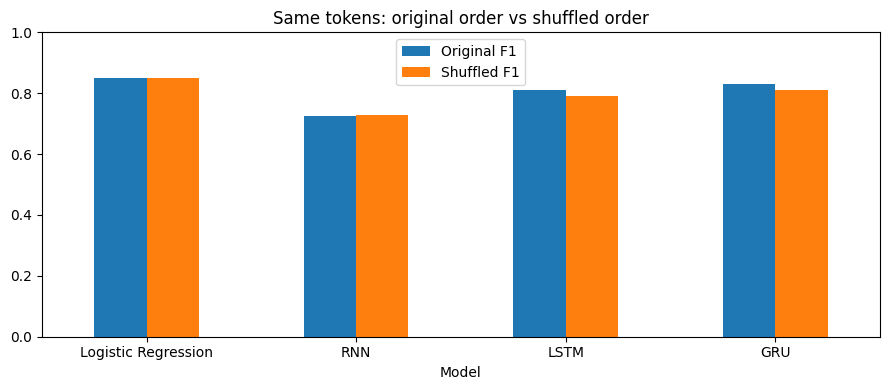

Maximum TF-IDF feature difference: 0.0


In [10]:
rng = np.random.default_rng(RANDOM_SEED)
retained_tokens = [tokenize(text)[:MODEL_MAX_LENGTH] for text in X_test]
ordered_texts = [" ".join(tokens) for tokens in retained_tokens]
shuffled_texts = [" ".join(rng.permutation(tokens).tolist()) for tokens in retained_tokens]
vectorizer = baseline_model.named_steps["tfidf"]
difference = vectorizer.transform(ordered_texts) - vectorizer.transform(shuffled_texts)
max_feature_difference = float(abs(difference).max())
assert max_feature_difference < 1e-12, "Unigram feature vectors should be identical"

order_rows = []
for name in ["Logistic Regression", "RNN", "LSTM", "GRU"]:
    if name == "Logistic Regression":
        original_p = baseline_model.predict_proba(ordered_texts)[:, positive_class]
        shuffled_p = baseline_model.predict_proba(shuffled_texts)[:, positive_class]
    else:
        original_p = exp4_outputs[name]["probabilities"]
        shuffled_p = predict_texts(exp4_outputs[name]["model"], shuffled_texts)
    original_pred = (original_p >= 0.5).astype(int)
    shuffled_pred = (shuffled_p >= 0.5).astype(int)
    original_f1 = f1_score(y_test_id, original_pred, zero_division=0)
    shuffled_f1 = f1_score(y_test_id, shuffled_pred, zero_division=0)
    order_rows.append({
        "Experiment": "Word order", "Model": name, "Max length": MODEL_MAX_LENGTH,
        "Samples": len(X_test), "Original F1": original_f1,
        "Shuffled F1": shuffled_f1, "F1 drop": original_f1 - shuffled_f1,
        "Changed predictions (%)": 100 * np.mean(original_pred != shuffled_pred),
        "Mean probability change": np.mean(abs(original_p - shuffled_p)),
    })
word_order_results = pd.DataFrame(order_rows)
display(word_order_results.round(4))
word_order_results.set_index("Model")[["Original F1", "Shuffled F1"]].plot(
    kind="bar", figsize=(9, 4), ylim=(0, 1), rot=0
)
plt.title("Same tokens: original order vs shuffled order")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "word_order.png", dpi=160, bbox_inches="tight")
plt.show()
print("Maximum TF-IDF feature difference:", max_feature_difference)


Trả lời bằng chứng thực nghiệm về word order

Kiểm tra sử dụng 9.916 mẫu test. Mỗi review được giới hạn 100 token trước khi xáo thứ tự, nên hai điều kiện có cùng token, cùng số lần xuất hiện và cùng độ dài. Sai khác lớn nhất giữa các vector TF-IDF bằng 0; Logistic Regression có F1 0,850477 ở cả hai thứ tự, không mẫu nào đổi nhãn và mean probability change bằng 0. F1 0,850477 này thấp hơn 0,908782 ở baseline đầy đủ vì ở đây TF-IDF cũng chỉ được nhận 100 token, không phải vì xáo thứ tự làm hỏng representation.

RNN đổi nhãn ở 23,5175% mẫu và xác suất positive thay đổi trung bình 0,188682. F1 tăng nhẹ từ 0,724635 lên 0,726846, tức tăng 0,002211. Vì vậy RNN có sử dụng thứ tự theo nghĩa prediction phụ thuộc thứ tự, nhưng không có bằng chứng rằng thứ tự gốc giúp tăng F1 trong kiểm tra này. Chênh lệch F1 nhỏ chưa được kiểm định độ ổn định qua nhiều lần shuffle hoặc nhiều seed. Tỷ lệ đổi nhãn cao cũng có thể phản ánh độ nhạy với vị trí cuối chuỗi hoặc sự thiếu ổn định, không đồng nghĩa hiểu cú pháp tốt.

LSTM đổi nhãn ở 9,4595% mẫu; F1 giảm từ 0,811171 xuống 0,790387, giảm 0,020784. GRU đổi nhãn ở 10,4175% mẫu; F1 giảm từ 0,831424 xuống 0,812125, giảm 0,019300. Khi giữ nguyên thông tin từ vựng mà phá thứ tự, hai model này giảm F1 khoảng 2 điểm phần trăm. Kết quả ủng hộ việc thứ tự gốc có đóng góp hữu ích cho prediction của LSTM/GRU trên tập đang kiểm tra.

Bằng chứng phù hợp nhất là kết hợp sự bất biến của TF-IDF với sự thay đổi của recurrent models, thay vì tuyên bố mọi recurrent model chắc chắn tốt hơn khi có word order. Shuffle cũng làm câu kém tự nhiên và thay vị trí token cuối; phép kiểm tra chưa tách riêng tác dụng của cú pháp, phạm vi phủ định và recency bias.


20. Experiment 5 — Sequence length

Tái sử dụng ba lần train RNN của Experiment 2; không train trùng.
Giữ architecture và hyperparameters cố định. CPU memory để NaN vì chỉ đo GPU peak memory.


,Model,Max length,Tokens retained (%),Training time (s),Validation loss,F1,Memory (MB)
0,RNN,50,21.6488,148.3085,0.6054,0.7166,NaN
1,RNN,100,41.8103,298.0611,0.5872,0.7246,NaN
2,RNN,200,68.9951,1051.7707,0.4964,0.8028,NaN


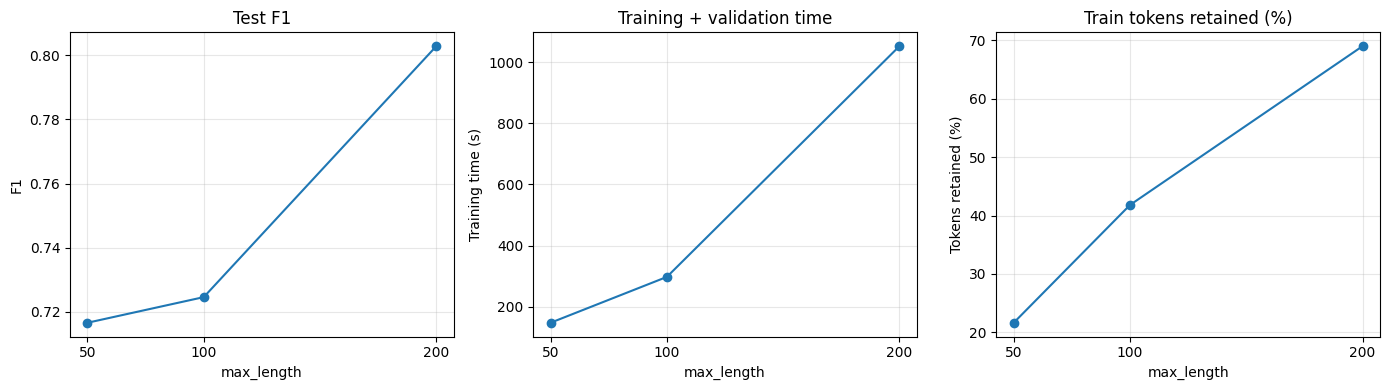

Đối chiếu F1, validation loss và thời gian; không giả định tăng max_length luôn tốt hơn.


In [11]:
experiment5_results = experiment2_results.copy()
experiment5_results["Experiment"] = "Experiment 5"
display(experiment5_results[["Model", "Max length", "Tokens retained (%)",
                            "Training time (s)", "Validation loss", "F1", "Memory (MB)"]].round(4))
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for axis, column, title in zip(
    axes, ["F1", "Training time (s)", "Tokens retained (%)"],
    ["Test F1", "Training + validation time", "Train tokens retained (%)"],
):
    axis.plot(experiment5_results["Max length"], experiment5_results[column], marker="o")
    axis.set(title=title, xlabel="max_length", ylabel=column, xticks=MAX_LENGTHS)
    axis.grid(True, alpha=0.3)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "sequence_length.png", dpi=160, bbox_inches="tight")
plt.show()
print("Đối chiếu F1, validation loss và thời gian; không giả định tăng max_length luôn tốt hơn.")


Trả lời Experiment 5 — Trade-off giữa context và computational cost

Experiment 5 dùng lại đúng các model RNN từ Experiment 2. Đây là phân tích khác của cùng ba lần train, không phải một lượt chạy độc lập xác nhận lại kết quả. Architecture, vocabulary, hidden dimension và số epoch được giữ cố định; chỉ thay max_length.

Tăng 50 lên 200 làm tỷ lệ token train giữ lại tăng từ 21,6488% lên 68,9951%, validation loss giảm từ 0,605418 xuống 0,496430 và test F1 tăng từ 0,716649 lên 0,802823. Đổi lại, thời gian tăng từ 148,3085 lên 1.051,7707 giây, xấp xỉ 7,09 lần. RNN vẫn có 1.288.385 tham số ở cả ba mức, nên chi phí tăng không xuất phát từ việc model có thêm weights. Chuỗi dài làm recurrent layer xử lý thêm timestep và làm graph phục vụ backpropagation dài hơn.

Có trade-off trong chính số liệu này: 200 token cho chất lượng tốt hơn nhưng tốn khoảng 17,53 phút so với 2,47 phút ở 50 token và 4,97 phút ở 100 token. Không suy ra rằng tăng độ dài bốn lần luôn làm thời gian tăng đúng bốn lần; phân phối độ dài thật, packed sequence, overhead và tải CPU cùng ảnh hưởng. 200 là cấu hình RNN có validation loss tốt nhất trong phạm vi đã thử; test F1 chỉ được dùng để báo cáo sau đánh giá, không dùng để lựa chọn cấu hình.

Cột Memory (MB) là NaN vì lượt chạy dùng CPU còn code chỉ đo GPU peak memory. Không được diễn giải NaN thành mức dùng RAM bằng 0, hoặc kết luận ba độ dài dùng bộ nhớ bằng nhau. Chưa có số đo RAM để lượng hóa trade-off về memory trong báo cáo này.


17. Bài tính LSTM gates

Forget gate gần 1 giữ phần lớn thông tin cũ; gần 0 loại bỏ phần lớn đóng góp của cell state cũ.


In [12]:
forget_gate, input_gate = 0.9, 0.2
candidate_state, previous_cell_state = 0.5, 0.8
new_cell_state = forget_gate * previous_cell_state + input_gate * candidate_state
assert np.isclose(new_cell_state, 0.82)
gate_results = pd.DataFrame([{
    "Experiment": "LSTM gate calculation", "Forget gate": forget_gate,
    "Input gate": input_gate, "Candidate state": candidate_state,
    "Previous cell state": previous_cell_state, "New cell state": new_cell_state,
}])
display(gate_results)


,Experiment,Forget gate,Input gate,Candidate state,Previous cell state,New cell state
0,LSTM gate calculation,0.9,0.2,0.5,0.8,0.82


Trả lời bài tính LSTM gates

Phần thông tin cũ được giữ là 0,9×0,8 = 0,72. Phần candidate được ghi thêm là 0,2×0,5 = 0,10. Vì vậy cell state mới bằng 0,72 + 0,10 = 0,82, khớp output. 0,82 là cell state mới, không phải trực tiếp hidden state hoặc xác suất sentiment; muốn tính hidden state còn cần output gate.

Forget gate gần 1 làm phần lớn cell state cũ đi qua bước cập nhật. Nếu giữ các giá trị khác và đặt forget gate bằng 1 thì cell state mới bằng 0,8 + 0,1 = 0,9. Forget gate gần 0 làm đóng góp của cell state cũ gần như mất đi; nếu bằng 0 thì cell state mới chỉ còn 0,1 từ candidate. Gate không quyết định độ quan trọng bằng một quy tắc ngôn ngữ có sẵn; weights của model học cách tạo gate từ input và trạng thái trước.


21. Experiment 6 — Long-range dependency

Cùng một prefix 100 token, chỉ đổi từ sentiment và vị trí của nó; tất cả đều nằm
trong đoạn model đọc, không bị truncation. Chạy cả RNN/LSTM/GRU để so sánh.
Các câu nhân tạo có thể không tự nhiên; thay đổi xác suất chỉ là quan sát thực nghiệm,
không phải phép đo gradient hay chứng minh đầy đủ vanishing gradient.


,Experiment,Model,Decision word,Position,Keyword in vocabulary,Max length,Truncated,Probability positive,Prediction
0,Experiment 6,RNN,wonderful,beginning,True,100,False,0.7600,positive
1,Experiment 6,RNN,wonderful,middle,True,100,False,0.7600,positive
2,Experiment 6,RNN,wonderful,end,True,100,False,0.8582,positive
3,Experiment 6,RNN,terrible,beginning,True,100,False,0.7599,positive
4,Experiment 6,RNN,terrible,middle,True,100,False,0.7599,positive
5,Experiment 6,RNN,terrible,end,True,100,False,0.2307,negative
6,Experiment 6,LSTM,wonderful,beginning,True,100,False,0.5266,positive
7,Experiment 6,LSTM,wonderful,middle,True,100,False,0.4789,negative
8,Experiment 6,LSTM,wonderful,end,True,100,False,0.5402,positive
9,Experiment 6,LSTM,terrible,beginning,True,100,False,0.0911,negative


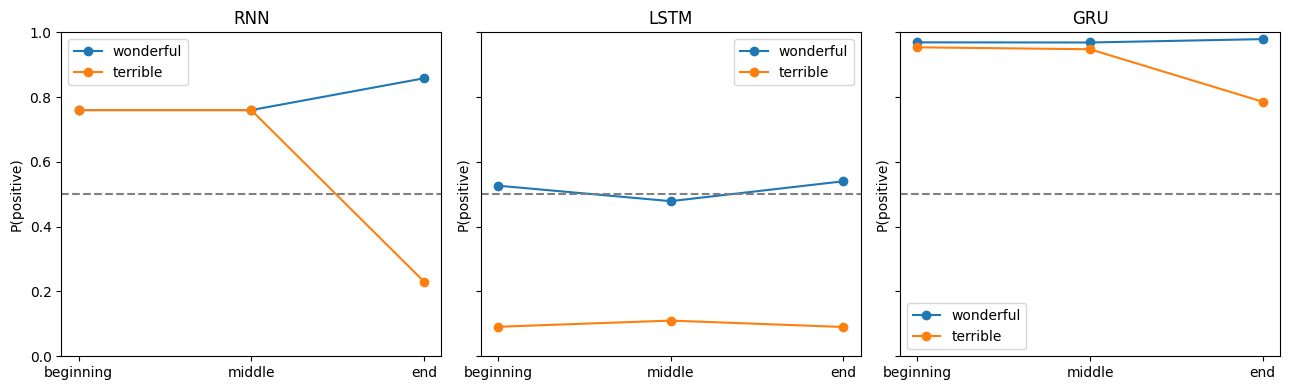

In [13]:
neutral_tokens = tokenize("the movie was released and the audience watched the film")
base_tokens = (neutral_tokens * 100)[:MODEL_MAX_LENGTH]
positions = [("beginning", 0), ("middle", 49), ("end", 99)]
long_range_rows = []
for architecture, output in exp4_outputs.items():
    for decision_word in ["wonderful", "terrible"]:
        for position_name, position in positions:
            tokens = base_tokens.copy()
            tokens[position] = decision_word
            text = " ".join(tokens)
            probability = float(predict_texts(output["model"], [text])[0])
            long_range_rows.append({
                "Experiment": "Experiment 6", "Model": architecture, "Text": text,
                "Decision word": decision_word, "Position": position_name,
                "Keyword in vocabulary": decision_word in vocab,
                "Max length": MODEL_MAX_LENGTH, "Truncated": False,
                "Probability positive": probability,
                "Prediction": "positive" if probability >= 0.5 else "negative",
            })
experiment6_results = pd.DataFrame(long_range_rows)
display(experiment6_results.drop(columns="Text").round(4))
fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
for axis, architecture in zip(axes, ["RNN", "LSTM", "GRU"]):
    for word in ["wonderful", "terrible"]:
        subset = experiment6_results[
            (experiment6_results["Model"] == architecture)
            & (experiment6_results["Decision word"] == word)
        ]
        axis.plot(subset["Position"], subset["Probability positive"], marker="o", label=word)
    axis.axhline(0.5, linestyle="--", color="gray")
    axis.set(title=architecture, ylabel="P(positive)", ylim=(0, 1))
    axis.legend()
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "long_range_dependency.png", dpi=160, bbox_inches="tight")
plt.show()


Nhận xét Experiment 6 — Vị trí từ sentiment

Các câu có cùng độ dài 100 token; 'wonderful' và 'terrible' đều có trong vocabulary và đều nằm trong đoạn input được giữ. Do đó không thể giải thích các khác biệt ở đây bằng việc từ khóa bị truncate hoặc đổi thành UNK. Tuy vậy, nền câu lặp lại và một số vị trí thay thế có thể tạo câu thiếu tự nhiên; chưa có kết quả cho nền câu không chứa từ quyết định sentiment để đo riêng mức thiên lệch của nền.

Với RNN, P(positive) của 'wonderful' ở đầu/giữa/cuối là 0,759962/0,759967/0,858171; với 'terrible' là 0,759893/0,759879/0,230666. Ở đầu và giữa, hai từ trái nghĩa tạo xác suất gần như giống nhau quanh 0,76. Ở cuối, khoảng cách giữa hai xác suất tăng lên khoảng 0,6275 và nhãn đổi positive/negative đúng theo chiều sentiment của từ. Đây là biểu hiện phù hợp với việc RNN nhạy hơn với thông tin gần hidden state cuối trong các mẫu này.

Với LSTM, 'terrible' cho P(positive) 0,091070/0,110132/0,090459 và luôn được dự đoán negative. 'wonderful' cho 0,526616/0,478880/0,540206: nhãn lần lượt positive/negative/positive, trong đó các xác suất đều gần ngưỡng 0,5 hơn trường hợp 'terrible'. LSTM phân tách hai từ rõ hơn RNN ở đầu và giữa, nhưng vẫn sai với 'wonderful' ở giữa và không thể được mô tả là xử lý đúng mọi vị trí.

Với GRU, 'wonderful' cho 0,969046/0,968641/0,979032, còn 'terrible' cho 0,953810/0,947775/0,785766. Cả sáu trường hợp đều được dự đoán positive. Đặt 'terrible' cuối chuỗi làm xác suất giảm mạnh hơn so với đặt ở đầu/giữa, nhưng chưa đủ để vượt ngưỡng sang negative. Như vậy GRU có F1 test cao nhất trong ba model nhưng không phân loại tốt nhất ở bộ câu nhân tạo này; không được lấy bảng test tổng thể để mặc định GRU luôn hiểu dependency dài tốt nhất.

Quan sát thực nghiệm là prediction thay đổi theo vị trí và RNN phân biệt từ sentiment rõ nhất khi từ ở cuối. Giải thích lý thuyết có thể liên quan đến việc thông tin phải đi qua nhiều bước recurrent, nhưng experiment này không đo gradient, không so sánh nhiều độ dài và chỉ có một nền câu. Chưa đủ bằng chứng để khẳng định các số trên chứng minh vanishing gradient hoặc xác định đó là nguyên nhân duy nhất. Nên kiểm tra thêm nhiều nền câu tự nhiên, cặp sentiment và seed trước khi khái quát hóa.


23. Learning curves

Phân tích toàn bộ 10 epoch và checkpoint được chọn theo validation loss. Đối chiếu train loss, validation loss và validation F1 để tránh chỉ nhìn một epoch.


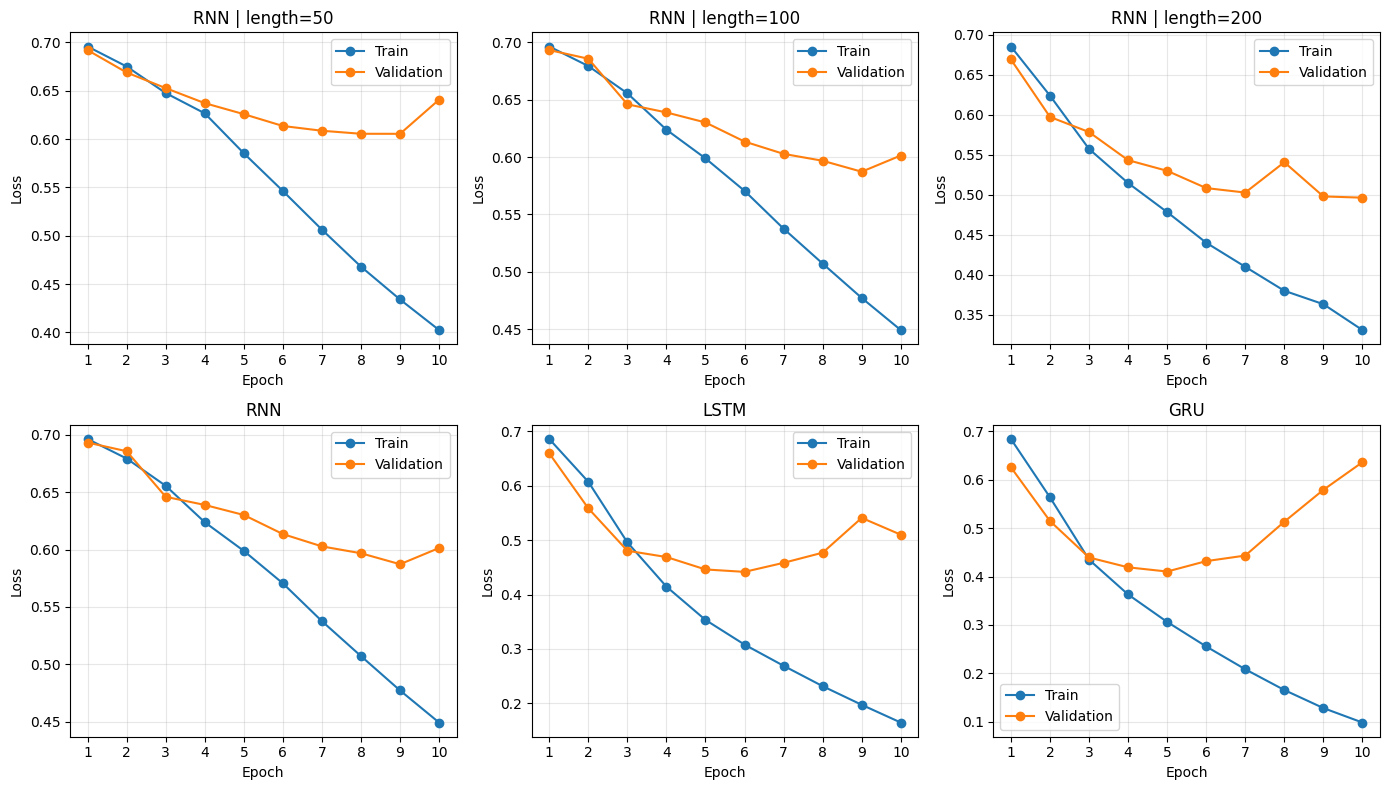

,Experiment,Model,Max length,Epoch,Train loss,Validation loss,Validation F1
0,Learning curves,RNN,50,1,0.6958,0.6920,0.5293
1,Learning curves,RNN,50,2,0.6750,0.6689,0.5585
2,Learning curves,RNN,50,3,0.6476,0.6527,0.6498
3,Learning curves,RNN,50,4,0.6266,0.6371,0.6563
4,Learning curves,RNN,50,5,0.5853,0.6258,0.6809
5,Learning curves,RNN,50,6,0.5463,0.6135,0.7107
6,Learning curves,RNN,50,7,0.5063,0.6086,0.6994
7,Learning curves,RNN,50,8,0.4680,0.6055,0.7067
8,Learning curves,RNN,50,9,0.4340,0.6054,0.7140
9,Learning curves,RNN,50,10,0.4024,0.6408,0.7096


In [14]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
curve_inputs = [(f"RNN | length={length}", experiment2_outputs[length]) for length in MAX_LENGTHS]
curve_inputs += [(name, exp4_outputs[name]) for name in ["RNN", "LSTM", "GRU"]]
for axis, (title, output) in zip(axes.flat, curve_inputs):
    history = output["history"]
    epochs = range(1, len(history["train_loss"]) + 1)
    axis.plot(epochs, history["train_loss"], marker="o", label="Train")
    axis.plot(epochs, history["validation_loss"], marker="o", label="Validation")
    axis.set(title=title, xlabel="Epoch", ylabel="Loss", xticks=list(epochs))
    axis.legend()
    axis.grid(True, alpha=0.3)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "learning_curves.png", dpi=160, bbox_inches="tight")
plt.show()

history_rows = []
unique_outputs = list(experiment2_outputs.values()) + [exp4_outputs["LSTM"], exp4_outputs["GRU"]]
for output in unique_outputs:
    for i, train_loss in enumerate(output["history"]["train_loss"]):
        history_rows.append({
            "Experiment": "Learning curves", "Model": output["result"]["Model"],
            "Max length": output["result"]["Max length"], "Epoch": i + 1,
            "Train loss": train_loss,
            "Validation loss": output["history"]["validation_loss"][i],
            "Validation F1": output["history"]["validation_f1"][i],
        })
history_results = pd.DataFrame(history_rows)
display(history_results.round(4))


Trả lời mục 23 — Model có dấu hiệu overfitting không?

RNN 50 token: train loss giảm từ 0,6958 ở epoch 1 xuống 0,4024 ở epoch 10. Validation loss giảm tới mức thấp nhất 0,605418 ở epoch 9, rồi tăng lên 0,640754 ở epoch 10 dù train loss tiếp tục giảm từ 0,434014 xuống 0,402406. Đây là dấu hiệu overfitting ở bước cuối; checkpoint epoch 9 được giữ lại, không dùng weights cuối epoch 10.

RNN 100 token: train loss giảm từ 0,696314 xuống 0,449250. Validation loss tốt nhất là 0,587208 ở epoch 9, sau đó tăng lên 0,601338 ở epoch 10. Dấu hiệu tách giữa train và validation xuất hiện ở cuối lượt chạy. Validation F1 lại tăng từ 0,710173 ở epoch 9 lên 0,733771 ở epoch 10; điều này không mâu thuẫn vì F1 chỉ dựa trên nhãn sau ngưỡng 0,5, còn cross-entropy còn xét độ tự tin của xác suất, đặc biệt các dự đoán sai.

RNN 200 token: train loss giảm từ 0,685291 xuống 0,331029. Validation loss giảm từ 0,669090 tới 0,502805 ở epoch 7, tăng tạm thời lên 0,540711 ở epoch 8, rồi giảm còn 0,497979 ở epoch 9 và 0,496430 ở epoch 10. Không có xu hướng validation loss tăng kéo dài ở cuối, nên chưa có bằng chứng overfitting cuối lượt rõ như hai cấu hình ngắn hơn. Khoảng cách train/validation cuối lượt vẫn khoảng 0,1654, cho thấy còn generalization gap; không thể kết luận model chắc chắn không overfit nếu train lâu hơn.

LSTM: validation loss đạt thấp nhất 0,441632 ở epoch 6 khi train loss là 0,307841. Từ epoch 7 trở đi, train loss tiếp tục giảm tới 0,164482, còn validation loss tăng lên 0,458252, 0,476916, 0,540914 rồi còn 0,510043. Dù có dao động, tất cả các mức validation loss sau epoch 6 đều cao hơn mức tốt nhất. Đây là dấu hiệu overfitting rõ hơn RNN 200 token; checkpoint epoch 6 là lựa chọn phù hợp tiêu chí validation loss.

GRU: validation loss thấp nhất là 0,410254 ở epoch 5, sau đó tăng lần lượt lên 0,431722, 0,443180, 0,512988, 0,578721 và 0,635723 ở epoch 10. Trong khi đó train loss giảm từ 0,306341 ở epoch 5 xuống 0,098825 ở epoch 10. Sự phân kỳ kéo dài này là dấu hiệu overfitting mạnh nhất trong các curve đang quan sát. Checkpoint epoch 5 được dùng để test và Application; không phải model cuối epoch 10. Có thể thử early stopping theo validation loss, dropout hoặc weight decay ở một lượt kiểm tra sau, nhưng notebook chưa đo kết quả của các biện pháp đó.

Nhận xét trên dựa vào toàn bộ 10 epoch và các mốc validation loss, không chỉ nhìn loss ở epoch cuối. Chỉ có một seed, nên chưa có đánh giá độ ổn định của các mốc bắt đầu overfit.


22. Confusion matrices — cùng tập test


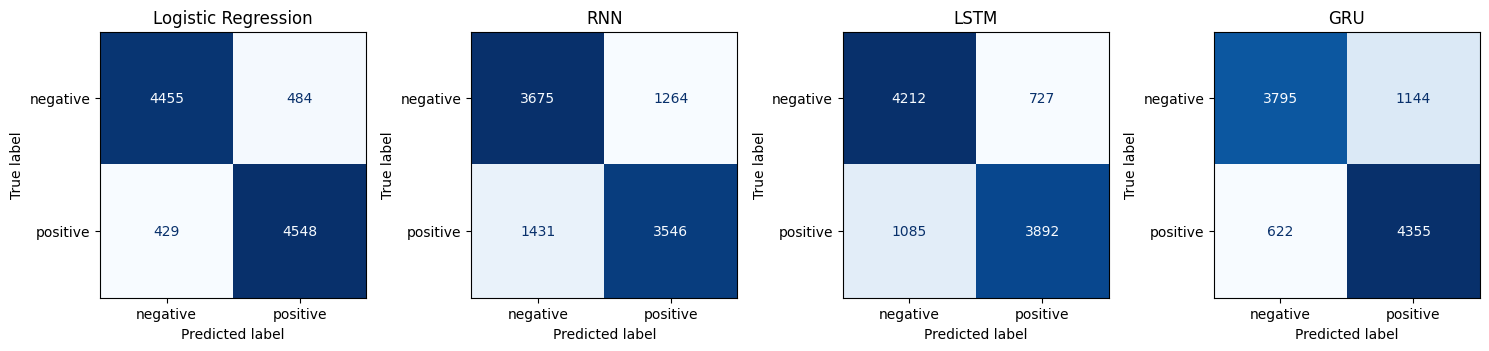

,Experiment,Model,TN,FP,FN,TP
0,Confusion matrix,Logistic Regression,4455,484,429,4548
1,Confusion matrix,RNN,3675,1264,1431,3546
2,Confusion matrix,LSTM,4212,727,1085,3892
3,Confusion matrix,GRU,3795,1144,622,4355


In [15]:
confusion_inputs = {"Logistic Regression": (y_test_id.astype(int), baseline_pred_ids)}
confusion_inputs.update({name: (out["y_true"], out["y_pred"]) for name, out in exp4_outputs.items()})
fig, axes = plt.subplots(1, 4, figsize=(15, 4))
confusion_rows = []
for axis, (name, (truth, prediction)) in zip(axes, confusion_inputs.items()):
    matrix = confusion_matrix(truth, prediction, labels=[0, 1])
    ConfusionMatrixDisplay(matrix, display_labels=["negative", "positive"]).plot(
        ax=axis, cmap="Blues", colorbar=False, values_format="d"
    )
    axis.set_title(name)
    tn, fp, fn, tp = matrix.ravel()
    confusion_rows.append({"Experiment": "Confusion matrix", "Model": name,
                           "TN": tn, "FP": fp, "FN": fn, "TP": tp})
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "confusion_matrix.png", dpi=160, bbox_inches="tight")
plt.show()
confusion_results = pd.DataFrame(confusion_rows)
display(confusion_results)


Nhận xét confusion matrix và diễn giải các metrics

Lớp positive được mã hóa là 1. TP là review positive dự đoán positive; TN là negative dự đoán negative; FP là negative bị dự đoán positive; FN là positive bị dự đoán negative. Test có 4.939 negative và 4.977 positive, tổng 9.916 mẫu.

Logistic Regression có TN=4.455, FP=484, FN=429, TP=4.548, tức 913 lỗi. RNN có TN=3.675, FP=1.264, FN=1.431, TP=3.546, tức 2.695 lỗi; số FN lớn cho thấy model còn bỏ sót nhiều review positive ở giới hạn 100 token. LSTM có TN=4.212, FP=727, FN=1.085, TP=3.892, tổng 1.812 lỗi. GRU có TN=3.795, FP=1.144, FN=622, TP=4.355, tổng 1.766 lỗi.

So với LSTM, GRU giảm 463 false negative nhưng tăng 417 false positive, nên chỉ giảm ròng 46 lỗi và accuracy tăng khoảng 0,46 điểm phần trăm. Tuy nhiên positive-class recall tăng khoảng 9,30 điểm phần trăm và F1 tăng khoảng 2,03 điểm phần trăm. Đây là lý do không nên chỉ nhìn accuracy 0,8219 so với 0,8173 rồi kết luận hai model gần như giống nhau.

Có thể kiểm tra trực tiếp metrics của GRU từ matrix: accuracy=(3.795+4.355)/9.916=0,821904; precision=4.355/(4.355+1.144)=0,791962; recall=4.355/(4.355+622)=0,875025; F1=2×4.355/(2×4.355+1.144+622)=0,831424. Các giá trị khớp bảng. F1 này dành cho lớp positive, không phải macro-F1 của hai lớp. Theo ma trận, GRU nhận diện negative đúng khoảng 76,84%, thấp hơn khoảng 85,28% của LSTM, nên ưu thế recall positive đi kèm đánh đổi ở lớp negative.


24. Error Analysis — 3 đúng và 3 sai

Bảng chọn review thật từ test. Các cột chẩn đoán xét đúng prefix model nhìn thấy,
không gán nguyên nhân chỉ vì review đầy đủ có một từ `not`.
Sarcasm, ambiguous sentiment, domain-specific terms và noise cần đọc ngữ cảnh;
các nhận xét dưới đây là bằng chứng/gợi ý kiểm tra, không phải xác nhận nguyên nhân.


In [16]:
output = exp4_outputs[best_architecture]
error_table = pd.DataFrame({
    "Text": X_test.to_numpy(), "True": y_test.to_numpy(),
    "Predicted": np.where(output["y_pred"] == 1, "positive", "negative"),
    "Probability positive": output["probabilities"],
})
error_table["Correct"] = error_table["True"] == error_table["Predicted"]
error_table["Error type"] = np.where(
    error_table["Correct"], "Correct",
    np.where(error_table["Predicted"] == "positive", "False Positive", "False Negative"),
)

def select_examples(frame, count=3):
    # Include both true classes when possible, then fill the remaining rows.
    first = frame.groupby("True", sort=False).head(1)
    rest = frame.drop(index=first.index)
    return pd.concat([first, rest]).head(count)

correct_examples = select_examples(error_table[error_table["Correct"]])
incorrect_examples = select_examples(error_table[~error_table["Correct"]])
assert len(correct_examples) == 3 and len(incorrect_examples) == 3
selected = pd.concat([correct_examples, incorrect_examples]).copy()

def diagnostic_fields(row):
    tokens = tokenize(row["Text"])
    seen = tokens[:MODEL_MAX_LENGTH]
    negation = sorted({token for token in seen
                       if token in {"not", "no", "never", "neither", "nor"} or token.endswith("n't")})
    contrast = sorted(set(seen) & {"but", "however", "although", "though", "yet"})
    unknown = sorted({token for token in seen if token not in vocab})
    rare = sorted({token for token in seen if counter[token] <= 2})
    facts = []
    if len(tokens) > MODEL_MAX_LENGTH:
        facts.append(f"Chỉ đọc {MODEL_MAX_LENGTH}/{len(tokens)} token; cần đối chiếu phần bị cắt")
    if negation:
        facts.append("Có phủ định trong input: " + ", ".join(negation))
    if contrast:
        facts.append("Có tương phản trong input: " + ", ".join(contrast))
    if unknown:
        facts.append(f"Có {len(unknown)} từ khác nhau bị đổi thành UNK")
    if not facts:
        facts.append("Chưa thấy phủ định/tương phản/UNK/truncation theo kiểm tra này")
    verdict = ("Dự đoán đúng; không suy ra model đã hiểu mọi quan hệ ngữ nghĩa."
               if row["Correct"] else
               "Dự đoán sai; chưa đủ bằng chứng quy lỗi cho sequence modeling. "
               "Cần đọc sentiment chính, vị trí từ khóa và dữ liệu huấn luyện.")
    return pd.Series({
        "Token count": len(tokens), "Seen text": " ".join(seen),
        "Truncated": len(tokens) > MODEL_MAX_LENGTH,
        "Negation in input": ", ".join(negation), "Contrast in input": ", ".join(contrast),
        "Unknown words": ", ".join(unknown), "Rare words": ", ".join(rare),
        "UNK rate (%)": 100 * sum(token not in vocab for token in seen) / max(1, len(seen)),
        "Analysis": "; ".join(facts) + ". " + verdict,
        "Sequence modeling assessment": "Chưa xác định chỉ từ prediction",
        "Manual checks": "long-range dependency; sarcasm; ambiguous sentiment; domain-specific term; noise",
    })

selected = pd.concat([selected, selected.apply(diagnostic_fields, axis=1)], axis=1)
selected["Experiment"] = "Error analysis"
selected["Model"] = best_architecture
error_analysis_results = selected.reset_index(drop=True)
print("Model selected by validation:", best_architecture)
print("Test errors:", int((~error_table["Correct"]).sum()), "/", len(error_table))
with pd.option_context("display.max_colwidth", None):
    display(error_analysis_results[["Text", "True", "Predicted", "Analysis"]])
display(error_analysis_results[["Correct", "Error type", "Token count", "Truncated",
                                "Negation in input", "Contrast in input", "UNK rate (%)"]])


Model selected by validation: GRU
Test errors: 1766 / 9916


,Text,True,Predicted,Analysis
0,"The word ""boring"" gets thrown around way too often when referring to exactly how bad a low-budget Horror movie might, or might not be. I've seen many a B-movie. Many horrible, terribly inept B-movies. Some with a production value of a few hundred bucks. Does ineptness, lousy acting, worse continuity, and embarrassing budgets really make a movie unwatchable? Some would no doubt way yes. Most of which are probably huge fans of The Matrix. Well, I hate big-budget movies, so I say no. Bad can sometimes be funny (Blood Freak), sometimes even mind-blowing (Troll 2), but Boring will always be unwatchable... Hey, kinda like Bloodthirsty Butchers, which reminds me, I'm writing a review for this pile of garbage... Uh, yeah, anyway. This is one of late British director Andy Milligan's many alternatives to sleeping pills. This one is based on Sweeney Todd... Great. Milligan takes a boring story, and still manages to ""butcher"" it. Hey, that's pretty funny, I said bu... sorry, I keep getting distracted. This isn't exactly easy. On second thought, I'll make it easy. No gore, no scares, no entertainment, just unlikeable, annoying people having incoherent conversations. that's Bloodthirsty Butchers. Oh yeah, and something about a barber killing people, and something or other about meat pies. I don't know, it's not important. For something a little more rewarding from Andy Milligan, there's always the only other one I've seen, The Rats Are Coming, The Werewolves Are Here. Yeah, you heard me. But hows about we forget about this Milligan guy all together, and pick up something sweet like Sick Girl or Teenape Goes To Camp. Whatever you decide, just know, Bloodthirsty Butchers sucks, possibly even more than any other version of this already lackluster tale. And that, B-movie fans, is really saying something. 2/10",negative,negative,"Chỉ đọc 100/304 token; cần đối chiếu phần bị cắt; Có phủ định trong input: no, not. Dự đoán đúng; không suy ra model đã hiểu mọi quan hệ ngữ nghĩa."
1,"Absolutely, I agree with my previous commentator in describing this as a riveting,fascinating and certainly beautiful film. It's not necessary to see all the episodes,since the first ones are the best,while the last ones are a-bit tiresome,but for any person who likes German's and their good-natured ways,all episodes are worth seeing.In typical german fashion, values are constantly questioned,even it's murderous Nazi past is confronted in the last episodes, the rich dialogues are particularly interesting. These episodes are recommended for anyone who is about to live or travel in Germany,preferably in original language!!",positive,positive,Chỉ đọc 100/102 token; cần đối chiếu phần bị cắt; Có phủ định trong input: not; Có tương phản trong input: but; Có 1 từ khác nhau bị đổi thành UNK. Dự đoán đúng; không suy ra model đã hiểu mọi quan hệ ngữ nghĩa.
2,"Producers Golan and Globus should have been ashamed to release this piece of trash publicly. I know this is gonna sound cliched, but compared to this, the first ""Hercules"" of 1983 looks like a mature and exciting epic! This ""sequel"" is moronic, cheap, unredeemable, childish, phony, inept and BADLY ACTED. A landmark in bad cinema, and one of the few, few movies I've seen that REALLY deserve the lowest possible rating: no stars!",negative,negative,Có phủ định trong input: no; Có tương phản trong input: but; Có 2 từ khác nhau bị đổi thành UNK. Dự đoán đúng; không suy ra model đã hiểu mọi quan hệ ngữ nghĩa.
3,"A CBS radio program entitled ""We the People"" assists in finding an American home for Vienna refugee Charles Coburn (as Karl Braun), a skilled surgeon and pool hustler. He arrives with beautiful daughter Sigrid Gurie (as Leni), who is ""studying"" to become a nurse. Relocated to a small, dusty Midwestern village, they are welcomed at the station by burly John Wayne (as John Phillips) and his uncle Spencer Charters (as 'Nunk' Atterbury), a veterinarian. Ms. Gurie is unhappy in the d

,Correct,Error type,Token count,Truncated,Negation in input,Contrast in input,UNK rate (%)
0,True,Correct,304,True,"no, not",,0.000000
1,True,Correct,102,True,not,but,1.000000
2,True,Correct,73,False,no,but,2.739726
3,False,False Positive,224,True,,but,13.000000
4,False,False Negative,317,True,"doesn't, wouldn't",,3.000000
5,False,False Positive,237,True,,but,5.000000


Phân tích cụ thể 3 mẫu đúng và 3 mẫu sai

Model được phân tích là GRU tại checkpoint epoch 5, được chọn bằng validation. Trong các đoạn dưới, P là P(positive), không phải luôn là xác suất của nhãn dự đoán. Số thứ tự mẫu theo đúng sáu dòng của bảng phía trên. Các vị trí token được đếm từ 1 bằng tokenizer của notebook. Vì model chỉ đọc 100 token đầu, cần tách lỗi do mất input khỏi lỗi sử dụng context đã có trong input. Các xác suất dưới đây là output của model, chưa có bước đánh giá calibration để xem chúng có tương ứng tần suất đúng thực tế hay không.


Mẫu đúng 1 — Review bắt đầu bằng 'The word "boring" gets thrown around...'

Nhãn thật negative, dự đoán negative; P(positive)=0,006658, tương ứng xác suất nhãn negative 0,993342. Review có 304 token, chỉ 100 token đầu được đọc, UNK rate 0%. Trong prefix đã có nhiều mô tả tiêu cực như 'horrible', 'terribly inept', 'lousy acting', 'worse continuity', 'embarrassing budgets' và 'unwatchable'. Các tín hiệu này có thể giúp model dự đoán negative dù phần lớn review bị cắt.

Prefix cũng có sắc thái không đơn giản: người viết cho rằng phim dở đôi khi vẫn 'funny' hoặc 'mind blowing', và 'might not be' không thể được đọc như một từ khóa negative độc lập. Dự đoán đúng cho thấy các tín hiệu tổng hợp trong prefix đủ dẫn tới nhãn đúng ở mẫu này, nhưng không chứng minh model đã xử lý đúng từng câu phủ định. Cụm mỉa mai 'alternatives to sleeping pills' bắt đầu ở token 137, nằm ngoài input; vì vậy không được lấy prediction này làm bằng chứng GRU hiểu sarcasm của cụm đó.


Mẫu đúng 2 — Review bắt đầu bằng 'Absolutely, I agree with my previous commentator...'

Nhãn thật positive, dự đoán positive với P(positive)=0,977438. Review có 102 token và bị cắt hai token cuối 'original language'; UNK rate trong prefix là 1%, với từ "german's". Phần input vẫn chứa 'riveting', 'fascinating', 'beautiful film', 'the best', 'worth seeing', 'particularly interesting' và 'recommended'. Hai token bị cắt không phải phần duy nhất mang sentiment, nên truncation ít nghiêm trọng hơn ở các mẫu sai bên dưới.

Câu 'It's not necessary to see all the episodes' có phủ định nhưng không phải phủ định chất lượng phim. Review còn chê các tập cuối 'tiresome' rồi dùng 'but' để chuyển về đánh giá đáng xem. Dự đoán positive phù hợp sentiment tổng thể của đoạn được giữ. Có UNK và từ mang nghĩa tiêu cực như 'murderous Nazi past' nhưng đó là chủ đề được phim đề cập, không nhất thiết là lời chê phim. Mẫu này cho thấy không thể quy mọi lỗi cho việc có UNK, negation hoặc một từ tiêu cực; đối tượng mà các từ đang nói tới mới quan trọng.


Mẫu đúng 3 — Review bắt đầu bằng 'Producers Golan and Globus should have been ashamed...'

Nhãn thật negative, dự đoán negative; P(positive)=0,010872, tức xác suất negative 0,989128. Review có 73 token nên được đọc đầy đủ. Hai token 'globus' và 'unredeemable' không có embedding riêng, tạo UNK rate 2,739726%; tuy vậy còn nhiều dấu hiệu chê rõ như 'piece of trash', 'moronic', 'cheap', 'childish', 'phony', 'inept', 'BADLY ACTED', 'lowest possible rating' và 'no stars'.

Câu so sánh với 'Hercules' chứa từ tích cực 'mature and exciting epic', nhưng đang dùng một phim khác để hạ thấp phim được đánh giá. Model vẫn dự đoán đúng tổng thể. Đây là kết quả phù hợp với việc nhiều tín hiệu negative còn lại lấn át đoạn so sánh; chưa có phép loại bỏ từng cụm để xác định model có thực sự phân biệt đúng đối tượng của lời khen hay chỉ dựa vào mật độ từ chê. Không có truncation ở mẫu này, nên không cần dùng mất phần đuôi để giải thích prediction.


Mẫu sai 1 — Review 'A CBS radio program entitled "We the People"...'

Nhãn thật negative nhưng GRU dự đoán positive với P(positive)=0,716906; đây là false positive. Review dài 224 token và chỉ giữ 100 token. UNK rate 13% là cao nhất trong sáu mẫu được chọn, với 13 lần xuất hiện token không có embedding riêng, thuộc 12 từ khác nhau. Phần lớn là tên riêng hoặc từ liên quan bối cảnh như 'Gurie', 'Atterbury', 'dustbowl', 'veterinarian', nên có rủi ro mất chi tiết về nhân vật và ngữ cảnh, nhưng không thể khẳng định các từ này đều quyết định sentiment.

Prefix chủ yếu tóm tắt cốt truyện: người tị nạn, công việc phẫu thuật, con gái, ngôi làng và khả năng có tình cảm với John Wayne. Những cụm như 'skilled surgeon', 'beautiful daughter', 'welcomed' và 'romance' có sắc thái tích cực nhưng mô tả nội dung phim, không phải trực tiếp khen chất lượng phim. Câu đánh giá rõ 'This film does not flatter Wayne' bắt đầu ở token 173; nhận xét việc ghép đôi diễn viên 'doesn't help' cũng nằm sau giới hạn 100. Model đã mất phần chê phim rõ hơn ở phía sau.

Với bằng chứng hiện có, truncation và việc prefix thiên về kể cốt truyện là giải thích có cơ sở hơn tuyên bố GRU không hiểu phủ định. Phủ định trong câu đánh giá chính nằm ngoài input, nên model không có cơ hội xử lý nó. UNK rate cao có thể góp phần nhưng chưa có thử nghiệm thay token hoặc mở rộng vocabulary để tách ảnh hưởng. Đây chưa phải bằng chứng trực tiếp lỗi long-range dependency của recurrent layer. Một kiểm tra tiếp theo phù hợp là so prediction khi dùng phần đuôi hoặc giới hạn dài hơn; notebook hiện chưa chạy đối chứng đó cho riêng review này.


Mẫu sai 2 — Review bắt đầu bằng 'From a modern sensibility, it's sometimes hard to watch older films...'

Nhãn thật positive nhưng dự đoán negative, P(positive)=0,362043 và xác suất negative=0,637957; đây là false negative. Review dài 317 token, UNK rate trong prefix là 3%, gồm 'wallflower', 'inconstant' và 'ick'. 100 token đầu tập trung chê một subplot và cách xây dựng nhân vật: 'annoying', 'stupid', 'shallow', "wouldn't trust", 'dumb' và thái độ khó chịu của người viết. Nếu chỉ xét đoạn này, dự đoán negative là có thể hiểu được.

Điểm đổi trọng tâm 'Apart from that subplot, I did like the movie' bắt đầu ở token 142, hoàn toàn ngoài phần model nhận. Các lời khen các màn nhảy, trang phục, sân khấu và câu 'the dancing was worth watching' ở token 251 cũng bị cắt. Vì vậy nhãn positive của toàn review không được thể hiện đầy đủ trong prefix 100 token đang dùng để suy luận.

Nguyên nhân có bằng chứng rõ nhất ở mẫu này là mất phần context tích cực do truncation và khác biệt giữa đánh giá subplot với đánh giá toàn bộ phim. Không thể nói model đã quên một thông tin positive ở xa khi thông tin đó chưa từng đi vào model. Hai từ phủ định "wouldn't" và "doesn't" có trong input, nhưng chúng thực sự đi cùng các nhận xét tiêu cực về nhân vật; chỉ có sự xuất hiện của phủ định không đủ để kết luận model xử lý negation sai. Việc có ba UNK cũng chưa phải nguyên nhân chính được chứng minh, vì ngay cả khi đọc được các từ đó thì prefix vẫn phần lớn là lời chê.


Mẫu sai 3 — Review 'Incident on and off a Mountain Road...'

Nhãn thật negative nhưng dự đoán positive với P(positive)=0,767394; đây là false positive. Review có 237 token, UNK rate trong prefix là 5%, gồm các token 'coscarelli', "coscarelli's", 'garris', 'irresistibly' và 'tep'. Một số là tên tác giả/tác phẩm hoặc thành phần tên phim, nên vocabulary có thể làm yếu thông tin về đối tượng đang được nói tới; chưa có đối chứng để lượng hóa ảnh hưởng này.

Ngay trong 100 token đầu có lời khen các tác phẩm trước như 'cult gems', 'irresistibly weird' và 'great', rồi vế 'but he brings none of the qualities that made those films great to this TV episode'. 'But' ở token 41 và 'none of the qualities' bắt đầu ở token 44, nên phép phủ định/tương phản quan trọng đã có trong input. Cột 'Negation in input' vẫn rỗng vì bộ từ khóa trong code chưa chứa 'none'; không được diễn giải ô rỗng thành câu không có phủ định.

Đây là mẫu có cơ sở để nghi ngờ model sử dụng chưa tốt phạm vi của 'none' hoặc quan hệ giữa lời khen phim cũ và lời chê tập phim hiện tại. Khác hai mẫu sai trước, không thể quy toàn bộ lỗi cho mất câu đánh giá chính, vì một dấu hiệu chê quan trọng vẫn nằm trong prefix. Tuy nhiên các câu chê rõ hơn như 'really ridiculous' bắt đầu ở token 110 và các nhận xét 'so silly' ở phần sau đều bị cắt, nên truncation cũng góp phần làm lời chê kém đầy đủ.

Lỗi có thể liên quan sequence/context modeling vì cần kết hợp từ nối tương phản, phạm vi phủ định và đối tượng của lời khen. Đây vẫn là giả thuyết có căn cứ, chưa phải kết luận duy nhất: từ hiếm, tên riêng, dữ liệu huấn luyện và việc câu bị cắt cùng tồn tại. Cần thử cặp câu đối chứng giữ nguyên token nhưng đổi phạm vi 'none' hoặc cung cấp đầy đủ review trước khi quy trách nhiệm riêng cho GRU. Review đang chê khá trực tiếp; chưa có bằng chứng bắt buộc phải dùng sarcasm để giải thích lỗi.


Kết luận Error Analysis

Trong ba mẫu sai được chọn có hai false positive và một false negative, nhưng cách chọn ba mẫu không đại diện tỷ lệ lỗi toàn tập test. Hai review mất phần đánh giá quan trọng ở sau token 100; một review đã có phủ định/tương phản trong prefix nhưng vẫn bị dự đoán sai. Vì vậy có ít nhất hai nhóm vấn đề cần phân biệt: giới hạn đầu vào làm mất thông tin, và model sử dụng context đã nhận chưa tốt. Không thể gộp cả ba thành 'GRU không hiểu câu'.

Các yếu tố cần xem xét đã có bằng chứng cụ thể: very long sequence và truncation ở cả ba lỗi; rare word/UNK ở tỷ lệ 13%, 3% và 5%; tên riêng và thuật ngữ trong miền phim; sentiment pha trộn hoặc nhắc tới nhiều đối tượng; negation và contrast ở các phạm vi khác nhau. Không có annotation riêng về sarcasm, noise hay domain-specific term để khẳng định tự động mọi yếu tố đó là nguyên nhân. Bộ dò từ khóa cũng bỏ sót 'none', nên bảng chẩn đoán chỉ hỗ trợ đọc review, không thay thế phân tích ngữ cảnh.


25. So sánh với LAB 04

Recurrent models cập nhật hidden state theo thứ tự, giữ được thông tin về prefix.
Average Word2Vec mất thứ tự khi lấy trung bình. Gates hỗ trợ điều khiển thông tin,
nhưng không bảo đảm dependency dài được học hoặc accuracy luôn cao hơn baseline.
RNN/LSTM/GRU vẫn có chi phí tuần tự, giới hạn state, mất context khi truncate và
phụ thuộc dữ liệu/vocabulary. Không cần train lại Word2Vec để điền bảng thuộc tính này.


In [17]:
comparison_table = pd.DataFrame({
    "TF-IDF + LR": {
        "Sparse representation": "Yes", "Dense representation": "No",
        "Word order": "No (unigram)", "Context-dependent state": "No",
        "Long dependency": "No", "Computational cost": "Low", "One vector per word": "No",
    },
    "Avg Word2Vec + LR": {
        "Sparse representation": "No", "Dense representation": "Yes",
        "Word order": "No", "Context-dependent state": "No",
        "Long dependency": "No", "Computational cost": "Low", "One vector per word": "Yes",
    },
    **{name: {
        "Sparse representation": "No", "Dense representation": "Yes",
        "Word order": "Yes", "Context-dependent state": "Yes",
        "Long dependency": "Limited" if name == "RNN" else "Improved",
        "Computational cost": "Higher", "One vector per word": "Embedding",
    } for name in ["RNN", "LSTM", "GRU"]},
})
comparison_table.index.name = "Property"
display(comparison_table)
display(pd.concat([experiment3_results.iloc[[0]], experiment4_results], ignore_index=True)[
    ["Model", "Accuracy", "Precision", "Recall", "F1", "Training time (s)"]
].round(4))
comparison_export = comparison_table.reset_index().melt(
    id_vars="Property", var_name="Model", value_name="Value"
)
comparison_export["Experiment"] = "Section 25 comparison"


,TF-IDF + LR,Avg Word2Vec + LR,RNN,LSTM,GRU
Property,,,,,
Sparse representation,Yes,No,No,No,No
Dense representation,No,Yes,Yes,Yes,Yes
Word order,No (unigram),No,Yes,Yes,Yes
Context-dependent state,No,No,Yes,Yes,Yes
Long dependency,No,No,Limited,Improved,Improved
Computational cost,Low,Low,Higher,Higher,Higher
One vector per word,No,Yes,Embedding,Embedding,Embedding


,Model,Accuracy,Precision,Recall,F1,Training time (s)
0,Logistic Regression,0.9079,0.9038,0.9138,0.9088,8.6380
1,RNN,0.7282,0.7372,0.7125,0.7246,298.0611
2,LSTM,0.8173,0.8426,0.7820,0.8112,919.8810
3,GRU,0.8219,0.7920,0.8750,0.8314,635.1304


Trả lời mục 25 — Recurrent models giải quyết điều gì và còn vấn đề gì?

Average Word2Vec gom vector từ bằng trung bình, nên không giữ trực tiếp vị trí và quan hệ thứ tự. RNN/LSTM/GRU nhận từng token cùng trạng thái từ prefix trước đó, nhờ vậy có thể biểu diễn khác nhau cho 'good ... not bad' và 'bad ... not good', hoặc kết hợp một từ phủ định với từ sentiment theo sau. Đây là khác biệt về cơ chế; bằng chứng trong notebook là xáo cùng tập token không làm TF-IDF thay đổi, nhưng làm thay đổi prediction của cả ba recurrent model và giảm F1 của LSTM/GRU.

Những vấn đề còn lại xuất hiện ngay trong output. RNN không phân biệt rõ 'wonderful' và 'terrible' ở đầu/giữa chuỗi nhân tạo. GRU có test F1 0,8314 nhưng vẫn gọi positive ở mọi vị trí của 'terrible' trong Experiment 6. LSTM/GRU có validation loss tăng ở cuối dù train loss giảm. Ba mẫu lỗi còn cho thấy mất kết luận sentiment do truncation, tỷ lệ UNK và khó xác định đối tượng của lời khen. Các gates hỗ trợ information flow nhưng không bảo đảm hiểu ngôn ngữ hoặc giữ mọi context.

Về cost, LSTM và GRU cần 919,8810 và 635,1304 giây trong khi baseline cần 8,6380 giây theo cách đo đã nêu. Baseline F1 0,9088 vẫn cao nhất trong các model đã đo. Không có kết quả train Average Word2Vec + LR trong lượt notebook này, nên bảng thuộc tính không được dùng để suy ra một F1 hoặc thứ hạng thực nghiệm chưa được báo cáo cho model đó. Các recurrent layer ở đây vẫn dùng embedding ban đầu theo từng từ; phần phụ thuộc context nằm ở hidden state được cập nhật sau khi đọc prefix.


26. Application

Raw review → tokenizer → vocabulary → IDs → padding/truncation → embedding →
LSTM/GRU → linear → sigmoid → sentiment. Chọn LSTM/GRU bằng validation F1.
Hiển thị P(positive) và xác suất của nhãn dự đoán.

Mỗi ví dụ có một bản sửa context để đo độ nhạy. Sự thay đổi xác suất là bằng chứng
chẩn đoán, không phải phép giải thích nhân quả. Review dài được đánh dấu phần bị cắt.


In [18]:
application_architecture = experiment4_results[
    experiment4_results["Model"].isin(["LSTM", "GRU"])
].sort_values(["Validation F1", "Validation loss"], ascending=[False, True]).iloc[0]["Model"]
application_model = exp4_outputs[application_architecture]["model"]

def predict_sentiment(text):
    probability = float(predict_texts(application_model, [text])[0])
    label = "positive" if probability >= 0.5 else "negative"
    return {"Prediction": label, "Probability positive": probability,
            "Predicted label probability": probability if label == "positive" else 1 - probability}

long_intro = (
    "I watched this movie during the weekend without knowing much about the story. "
    "The opening introduces several characters and spends time describing their daily routines. "
    "The main character travels to a small town and meets people who have different memories "
    "of the same event. The film follows their conversations and gradually reveals what happened. "
    "Some scenes take place at a railway station, while others follow the family at home. "
    "I paid attention to how each conversation changed the relationships between the characters. "
    "The director returns to an earlier scene from another point of view and connects details "
    "that seemed unrelated at first. There are quiet moments between the larger events, "
    "and the ending brings the different stories together. "
)
long_review = long_intro + "Overall, I loved the movie: the acting was excellent and the ending was wonderful."
application_cases = [
    {"Type": "Short review", "Text": "I really enjoyed this movie.",
     "Important context": "enjoyed", "Edited text": "I really watched this movie."},
    {"Type": "Long review", "Text": long_review,
     "Important context": "loved, excellent, wonderful (check whether retained)",
     "Edited text": long_intro + "Overall, I hated the movie: the acting was terrible and the ending was awful."},
    {"Type": "Negation", "Text": "This film was not good.",
     "Important context": "not good", "Edited text": "This film was good."},
    {"Type": "Contrast", "Text": "I thought the movie would be terrible, but it was surprisingly good.",
     "Important context": "but it was surprisingly good",
     "Edited text": "I thought the movie would be terrible, and it was terrible."},
]
application_rows = []
for case in application_cases:
    prediction = predict_sentiment(case["Text"])
    edited = predict_sentiment(case["Edited text"])
    tokens = tokenize(case["Text"])
    seen = tokens[:MODEL_MAX_LENGTH]
    edited_p = edited["Probability positive"]
    application_rows.append({
        "Experiment": "Application", "Model": application_architecture, **case, **prediction,
        "Token count": len(tokens), "Seen text": " ".join(seen),
        "Truncated": len(tokens) > MODEL_MAX_LENGTH,
        "UNK rate (%)": 100 * sum(t not in vocab for t in seen) / max(1, len(seen)),
        "Edited probability positive": edited_p,
        "Probability change": prediction["Probability positive"] - edited_p,
        "Same encoded input after edit": encode(case["Text"])[:MODEL_MAX_LENGTH]
            == encode(case["Edited text"])[:MODEL_MAX_LENGTH],
    })
application_results = pd.DataFrame(application_rows)
print("Application model (validation selection):", application_architecture)
display(application_results[["Type", "Text", "Prediction", "Probability positive",
                             "Predicted label probability", "Truncated", "Important context",
                             "Edited probability positive", "Probability change"]].round(4))
print("Nếu hai bản có cùng encoded prefix, model nhận cùng input dù sentiment ở phần bị cắt khác nhau.")


Application model (validation selection): GRU


,Type,Text,Prediction,Probability positive,Predicted label probability,Truncated,Important context,Edited probability positive,Probability change
0,Short review,I really enjoyed this movie.,positive,0.8352,0.8352,False,enjoyed,0.6593,0.1759
1,Long review,I watched this movie during the weekend withou...,positive,0.6990,0.6990,True,"loved, excellent, wonderful (check whether ret...",0.6990,0.0000
2,Negation,This film was not good.,negative,0.4518,0.5482,False,not good,0.6019,-0.1501
3,Contrast,"I thought the movie would be terrible, but it ...",negative,0.4867,0.5133,False,but it was surprisingly good,0.0482,0.4386


Nếu hai bản có cùng encoded prefix, model nhận cùng input dù sentiment ở phần bị cắt khác nhau.


Nhận xét Application — Giải thích từng input và context

Application dùng GRU tại checkpoint epoch 5 được chọn bằng validation. Với review ngắn 'I really enjoyed this movie.', P(positive)=0,835167 nên nhãn positive, xác suất của nhãn dự đoán là 83,52%. Khi thay 'enjoyed' bằng 'watched', P(positive) giảm còn 0,659285, giảm 0,175882. Vì hai câu ngắn giữ gần như cùng cấu trúc và không bị truncate, phép thay từ này ủng hộ việc 'enjoyed' đóng góp cho prediction tích cực trong ví dụ. Nó chưa phải phép giải thích nhân quả hoàn chỉnh cho toàn model.

Review dài có 132 token nhưng chỉ giữ 100; P(positive)=0,699012. Câu cuối chứa 'loved', 'excellent', 'wonderful' nằm trong 32 token bị loại. Khi thay kết luận đó bằng 'hated', 'terrible', 'awful', P(positive) vẫn đúng 0,699012 và cột 'Same encoded input after edit' là True. Hai review khác sentiment ở phần đuôi nhưng model nhận cùng token IDs ở prefix, nên output giống nhau là hệ quả trực tiếp của preprocessing. Không được giải thích prediction ban đầu bằng việc GRU đã đọc 'excellent' hoặc 'wonderful', và cũng không được lấy prediction positive làm bằng chứng model hiểu đúng kết luận toàn review.

Với phủ định 'This film was not good.', P(positive)=0,451775 và model dự đoán negative với xác suất nhãn negative=0,548225. Khi bỏ 'not', câu 'This film was good.' có P(positive)=0,601894 và đổi sang positive. Chênh lệch 0,150119 đi đúng chiều tác động của phủ định trong cặp câu này. Hai output còn khá gần ngưỡng 0,5 nên không nên mô tả đây là prediction negative có độ tự tin rất cao, hoặc suy ra model hiểu mọi kiểu phủ định.

Với tương phản 'I thought the movie would be terrible, but it was surprisingly good.', P(positive)=0,486734 nên model dự đoán negative, chỉ nhỉnh về negative 0,513266. Nếu lấy sentiment cuối của câu làm tiêu chí thì prediction này chưa phù hợp: vế sau 'but' cho biết đánh giá thực tế là tốt. Khi đổi thành '... and it was terrible.', P(positive) giảm mạnh còn 0,048164. Như vậy vế tích cực sau 'but' có ảnh hưởng rõ, nâng P(positive) khoảng 0,438570, nhưng chưa đủ làm prediction vượt 0,5.

Câu tương phản chỉ có 12 token, không bị truncate và UNK rate là 0%. Do đó không có bằng chứng quy lỗi này cho mất context hoặc thiếu từ trong vocabulary. Khả năng cần kiểm tra là cách model cân đối kỳ vọng 'would be terrible' với kết quả 'surprisingly good', phạm vi tương phản và độ bao phủ của kiểu câu này trong train. Đây cũng không phải kiểm tra dependency dài vì câu ngắn. Không nên tự đổi threshold chỉ để làm đúng một ví dụ; nếu muốn chọn threshold khác cần dùng validation và đánh giá lại theo một quy tắc thống nhất.


Đối chiếu năm prediction sau experiment

Phần này trả lời dựa trên output đã có, không được coi là ghi lại dự đoán trước khi train hoặc tạo lại mức Confidence sau khi đã biết kết quả. Prediction trước experiment trong bài viết riêng cần được giữ theo nội dung đã ghi ban đầu.

Prediction 1 — Model nào xử lý word order trực tiếp hơn? RNN có cơ chế xử lý trực tiếp hơn TF-IDF unigram vì hidden state được cập nhật theo thứ tự. Kiểm tra cho thấy 23,5175% nhãn RNN đổi khi xáo token, còn Logistic Regression không đổi nhãn và vector TF-IDF sai khác bằng 0. Tuy vậy F1 của RNN tăng nhẹ sau shuffle, nên bằng chứng chỉ xác nhận order sensitivity, không xác nhận thứ tự gốc luôn giúp RNN này phân loại tốt hơn.

Prediction 2 — RNN hay LSTM xử lý dependency dài tốt hơn? Về cơ chế, cell state và gates của LSTM có thể hỗ trợ duy trì thông tin qua nhiều timestep. Classification ở 100 token cho LSTM F1 0,8112 so với RNN 0,7246. Trong Experiment 6, LSTM phân biệt 'terrible' và 'wonderful' ở đầu/giữa rõ hơn RNN, nhưng 'wonderful' ở giữa vẫn bị gọi negative. Kết quả phù hợp với nhận định LSTM có lợi thế trong các điều kiện đã thử, chưa chứng minh một ưu thế tuyệt đối trên mọi dạng dependency.

Prediction 3 — Tăng sequence length từ 50 lên 200 ảnh hưởng training thế nào? Thời gian RNN thực đo tăng từ 148,3085 lên 1.051,7707 giây, tức khoảng 7,09 lần; F1 tăng 0,7166 lên 0,8028 và validation loss giảm 0,6054 xuống 0,4964. Chuỗi dài hơn cần thêm recurrent steps và tính gradient qua graph dài hơn. Không phải cứ số token tăng bốn lần thì thời gian buộc tăng đúng bốn lần, và notebook chưa đo CPU memory để định lượng phần bộ nhớ.

Prediction 4 — Truncate về 30 token có thể ảnh hưởng classification không? Có, vì các phần đưa ra đánh giá quyết định có thể nằm sau token 30. Ngay giới hạn 100 đã cắt mất câu chê ở token 173 và câu đổi sang khen ở token 142 trong Error Analysis; giới hạn 30 cũng không chứa các đoạn đó. Tuy nhiên notebook chưa train và đánh giá max_length=30, nên chưa có số liệu để kết luận accuracy/F1 hoặc tỷ lệ token giữ lại cụ thể ở 30 token.

Prediction 5 — LSTM có chắc chắn accuracy cao hơn RNN trên mọi dataset không? Không. Trong lượt chạy này, tại 100 token LSTM có accuracy 0,8173 cao hơn RNN 0,7282, nhưng chỉ là một dataset, một split và một seed. GRU còn có F1 0,8314 cao hơn LSTM 0,8112, trong khi TF-IDF + LR đạt 0,9088. Chất lượng phụ thuộc phần input được giữ, vocabulary, dữ liệu, tối ưu và regularization, không chỉ độ phức tạp của architecture. Không thể từ một kết quả thuận chiều suy ra mệnh đề 'mọi dataset'.


Trả lời các câu hỏi kiểm tra hiểu bài và giới hạn rút ra

Hidden state có ý nghĩa gì? Đó là vector được cập nhật từ token hiện tại và trạng thái trước, có thể biểu diễn thông tin của prefix để phục vụ classification. Nó không phải văn bản nguyên gốc được lưu nguyên vẹn, cũng không tự động bằng sentiment score. Linear layer và sigmoid mới biến hidden state cuối thành xác suất positive trong pipeline này.

Vì sao training loss giảm nhưng validation loss tăng? Model có thể khớp train ngày càng chặt, kể cả các đặc điểm riêng hoặc nhiễu, nhưng các thay đổi không cải thiện trên dữ liệu chưa dùng để cập nhật weights. GRU cho ví dụ rõ: từ epoch 5 tới 10, train loss giảm 0,306341 xuống 0,098825 còn validation loss tăng 0,410254 lên 0,635723. Chọn checkpoint theo validation giúp tránh dùng weights cuối đã kém tổng quát hơn theo loss.

Forget gate dùng để làm gì? Nó điều chỉnh lượng cell state cũ được giữ qua bước cập nhật. Giá trị gần 1 giữ phần lớn đóng góp cũ, gần 0 giảm mạnh đóng góp đó. GRU khác LSTM ở chỗ không có cell state riêng và dùng update/reset gates để điều chỉnh hidden state; ít nhóm biến đổi hơn là một lý do thường có ít tham số recurrent hơn khi cùng kích thước hidden.

Vì sao recurrent models vẫn tạo động lực cho attention? Muốn ảnh hưởng tới trạng thái cuối, một token đầu chuỗi phải truyền thông tin qua nhiều cập nhật; đồng thời phần review đã nhận cần được nén vào trạng thái phục vụ classifier. Kết quả từ sentiment đầu/giữa của RNN trong Experiment 6 cho thấy giới hạn có thể xuất hiện ngay trong các mẫu nhỏ. Attention cho phép truy cập trực tiếp các representation của nhiều token đã được cung cấp thay vì chỉ dựa vào đường truyền dài tới một trạng thái cuối. Tuy nhiên attention không tự khôi phục những token đã bị preprocessing truncate; cần tách vấn đề giới hạn đầu vào khỏi vấn đề cách model sử dụng input.

Các kết luận của notebook bị giới hạn bởi một seed, ba giá trị độ dài cho RNN và 10 epoch với một bộ hyperparameters. Experiment 5 tái sử dụng Experiment 2, không phải lặp độc lập. Chưa có thí nghiệm 30 token, đo gradient qua timestep, nhiều seed, đối chứng từng nguyên nhân lỗi hoặc số đo CPU memory. Các đề xuất dropout, weight decay, head-tail truncation hay tăng vocabulary là hướng kiểm tra tiếp theo, không phải các cải thiện đã được đo trong output này.


Export — cell cuối cùng

Một CSV duy nhất chứa dataset/split, configuration, core checks, experiment results,
histories, confusion matrices, 6 mẫu error analysis, bảng mục 25 và Application.
Giá trị trống ở cột không áp dụng cho loại kết quả đó là bình thường.


In [19]:
config_results = pd.DataFrame([{
    "Experiment": "Configuration", "Random seed": RANDOM_SEED,
    "Epochs": EPOCHS, "Batch size": BATCH_SIZE, "Vocabulary size": len(vocab),
    "Embedding dimension": EMBED_DIM, "Hidden dimension": HIDDEN_DIM,
    "Learning rate": LEARNING_RATE, "Optimizer": "Adam", "Device": str(DEVICE),
    "Python version": platform.python_version(), "PyTorch version": torch.__version__,
    "Scikit-learn version": sklearn.__version__, "Split ratios": "0.6/0.2/0.2",
    "Selected model": best_architecture, "Application model": application_architecture,
    "Selection criterion": "Validation F1; checkpoint by validation loss",
}])
all_results = pd.concat([
    config_results, experiment1_result, split_results, retention_results, core_results,
    gate_results, experiment2_results, experiment3_results, experiment4_results,
    experiment5_results, word_order_results, experiment6_results, history_results,
    confusion_results, error_analysis_results, comparison_export, application_results,
], ignore_index=True, sort=False)
first_columns = ["Experiment", "Model", "Architecture", "Representation", "Split",
                 "Max length", "Epochs", "Vocabulary size", "Parameters", "Training time (s)",
                 "Accuracy", "Precision", "Recall", "F1"]
all_results = all_results.reindex(columns=first_columns + [
    column for column in all_results.columns if column not in first_columns
])
assert len(error_analysis_results) == 6
assert len(comparison_export) == 35
assert len(application_results) == 4
all_results.to_csv(RESULTS_PATH, index=False, encoding="utf-8-sig", float_format="%.6f")
print("Saved:", RESULTS_PATH)
display(all_results.groupby("Experiment", sort=False).size().rename("Rows").to_frame())
print("Figures:", ", ".join(path.name for path in OUTPUT_DIR.glob("*.png")))


Saved: D:\Study\Study_Class\Semester_7\NLP\Lab\lab05\lab05_results.csv


,Rows
Experiment,
Configuration,1
Experiment 1,1
Dataset split,3
Token retention,9
Core RNN check,2
LSTM gate calculation,1
Experiment 2,3
Experiment 3,2
Experiment 4,3


Figures: confusion_matrix.png, dataset_analysis.png, learning_curves.png, long_range_dependency.png, model_comparison.png, sequence_length.png, word_order.png
